# Machine Learning — FIFA & Car Price Analysis
## SP26 Group Project

---

### Group Members

| # | Name | ID |
|---|------|----|
| 1 | Omar Hassan Ibrahim | 2401241409 |
| 2 | Ziad Khaled | 2401243947 |
| 3 | Amr Mostafa Etman | 2401246342 |
| 4 | Ammar Yasser Saiid | 2401246882 |
| 5 | Mazen Mohamed Shafiq | 2401244585 |

---

### Project Structure

| Assignment | Dataset | Tasks |
|---|---|---|
| Assignment 1 | Car Price Dataset | EDA, Preprocessing, Regression, KNN Classification, Visualization |
| Assignment 2 | FIFA Players Dataset | EDA, Preprocessing, Polynomial Regression, Logistic Regression, Naive Bayes, Cross-Validation |
| Assignment 3 | FIFA Players Dataset | Advanced Models, Hyperparameter Tuning, Ensembling, Unified Pipeline, Stability Assessment |


---

# Assignment 1 — Car Price Analysis

**Dataset:** `car_price.csv`

This assignment covers the full machine learning workflow applied to a car pricing dataset: exploratory data analysis, data cleaning and preprocessing, building a Linear Regression model for price prediction, and a K-Nearest Neighbors classifier for price category prediction.


In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

## Task 1: Exploratory Data Analysis (EDA)

In [4]:
df= pd.read_csv("car_price.csv")
df.dropna(subset=['price'], inplace=True)
print(f"numper of columns and rows : {df.shape}")
print("type of columns :")
print(df.dtypes)

print("statical summary of the data :")

df.describe()

numper of columns and rows : (68814, 10)
type of columns :
model            object
year            float64
price           float64
transmission     object
mileage         float64
fuelType         object
tax             float64
mpg             float64
engineSize      float64
Make             object
dtype: object
statical summary of the data :


,year,price,mileage,tax,mpg,engineSize
count,65352.000000,68814.000000,65389.000000,65390.000000,65381.000000,65356.000000
mean,2017.075713,16583.919261,23188.949043,116.977978,55.823222,1.635574
std,2.103071,9304.412707,21362.415899,64.108277,17.123016,0.560911
min,1996.000000,495.000000,1.000000,0.000000,0.300000,0.000000
25%,2016.000000,10167.250000,7164.000000,30.000000,47.900000,1.200000
50%,2017.000000,14495.000000,17526.000000,145.000000,55.400000,1.600000
75%,2019.000000,20359.750000,32500.000000,145.000000,62.800000,2.000000
max,2020.000000,145000.000000,323000.000000,580.000000,470.800000,6.600000


# Histogram (price distribution )

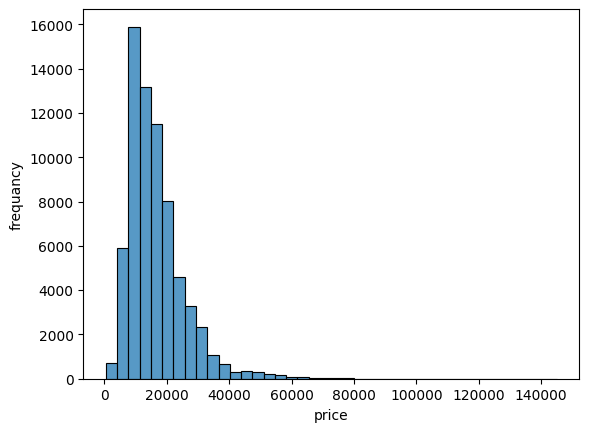

In [5]:
sns.histplot(df["price"] , bins=40)
plt.xlabel("price")
plt.ylabel("frequancy")
plt.show()

In [6]:
print(df.isna().sum())

model           3444
year            3462
price              0
transmission    3459
mileage         3425
fuelType        3461
tax             3424
mpg             3433
engineSize      3458
Make            3449
dtype: int64


In [7]:
corr = df.corr(numeric_only=True)
price_corr = corr["price"]
sorted_corr = price_corr.sort_values(ascending=False)
print(sorted_corr)

price         1.000000
engineSize    0.629839
year          0.519383
tax           0.353204
mpg          -0.335615
mileage      -0.427524
Name: price, dtype: float64


## Task 2 : Data Preprocessing

In [8]:
train, test = train_test_split(df, test_size=0.2, random_state=1)
print(f'Train: {train.shape}  |  Test: {test.shape}')

X = df.drop(columns='price')
y = df['price']

Train: (55051, 10)  |  Test: (13763, 10)


In [9]:
numeric_cols = train.select_dtypes(include=np.number).columns.tolist()
numeric_cols.remove('price')
print(numeric_cols)


cat_cols = train.select_dtypes(include="object").columns.tolist()
print(cat_cols)

for col in ['transmission', 'fuelType', 'Make']:
    print(df[col].value_counts())

['year', 'mileage', 'tax', 'mpg', 'engineSize']
['model', 'transmission', 'fuelType', 'Make']
transmission
Manual       38748
Semi-Auto    13892
Automatic    12711
Other            4
Name: count, dtype: int64
fuelType
Petrol      36483
Diesel      26052
Hybrid       2605
Other         208
Electric        5
Name: count, dtype: int64
Make
Ford       16142
vw         13698
BMW         9737
audi        9668
toyota      6065
skoda       5666
Hyundai     4389
Name: count, dtype: int64


# Handle the missing values

In [10]:
numeric_imputer = SimpleImputer(strategy='median')
train[numeric_cols] = numeric_imputer.fit_transform(train[numeric_cols])
test[numeric_cols] = numeric_imputer.transform(test[numeric_cols])

cat_imputer = SimpleImputer(strategy='most_frequent')
train[cat_cols] = cat_imputer.fit_transform(train[cat_cols])
test[cat_cols] = cat_imputer.transform(test[cat_cols])


print(train.isna().sum())

model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
Make            0
dtype: int64


### Deriving the Age Feature

The dataset contains a `year` column representing the car's manufacturing year. We derive a more interpretable `age` feature by subtracting from the current year (2025), then drop the original `year` column to avoid redundancy.

In [11]:
train['age'] = 2025 - train['year']
test['age']  = 2025 - test['year']

train.drop(columns=['year'], inplace=True)
test.drop(columns=['year'], inplace=True)

# one hot encoding (ohe)

In [12]:
enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

train_enc = enc.fit_transform(train[cat_cols])
test_enc  = enc.transform(test[cat_cols])
ohe_cols = enc.get_feature_names_out(cat_cols)

train_ohe = pd.DataFrame(train_enc,columns=ohe_cols,index=train.index)
test_ohe = pd.DataFrame(test_enc,columns=ohe_cols, index=test.index)

train_ohe

,model_ 1 Series,model_ 2 Series,model_ 3 Series,model_ 4 Series,model_ 5 Series,model_ 6 Series,model_ 7 Series,model_ 8 Series,model_ A1,model_ A2,...,fuelType_Hybrid,fuelType_Other,fuelType_Petrol,Make_BMW,Make_Ford,Make_Hyundai,Make_audi,Make_skoda,Make_toyota,Make_vw
70471,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
58577,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
8373,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
11672,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
20801,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51690,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
21659,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
22549,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
52695,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


# Scaling

In [13]:
num_features = train.select_dtypes(include=np.number).drop(columns=['price']).columns

ss = StandardScaler()

train[num_features] = ss.fit_transform(train[num_features])
test[num_features] = ss.transform(test[num_features])

print("Mean:")
print(train[num_features].mean())

print("Variance:")
print(train[num_features].var())

Mean:
mileage       9.551173e-18
tax          -4.491633e-17
mpg           4.597470e-16
engineSize   -2.457491e-16
age           1.841828e-16
dtype: float64
Variance:
mileage       1.000018
tax           1.000018
mpg           1.000018
engineSize    1.000018
age           1.000018
dtype: float64


In [14]:
train_final = pd.concat([train.drop(cat_cols, axis=1), train_ohe], axis=1)
test_final  = pd.concat([test.drop(cat_cols,  axis=1), test_ohe],  axis=1)
train_final.head()

,price,mileage,tax,mpg,engineSize,age,model_ 1 Series,model_ 2 Series,model_ 3 Series,model_ 4 Series,...,fuelType_Hybrid,fuelType_Other,fuelType_Petrol,Make_BMW,Make_Ford,Make_Hyundai,Make_audi,Make_skoda,Make_toyota,Make_vw
70471,7169.0,-0.207709,0.424715,0.109448,-0.792755,0.034647,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
58577,6388.0,0.186310,-1.882226,0.778310,-1.159951,0.034647,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
8373,13650.0,0.686676,0.424715,-0.026692,0.676028,1.012019,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
11672,18698.0,0.881294,0.424715,-0.026692,0.676028,0.034647,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
20801,13000.0,0.275060,0.106517,-0.210185,-0.241961,0.034647,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


# Boxplot (detect the outliers)

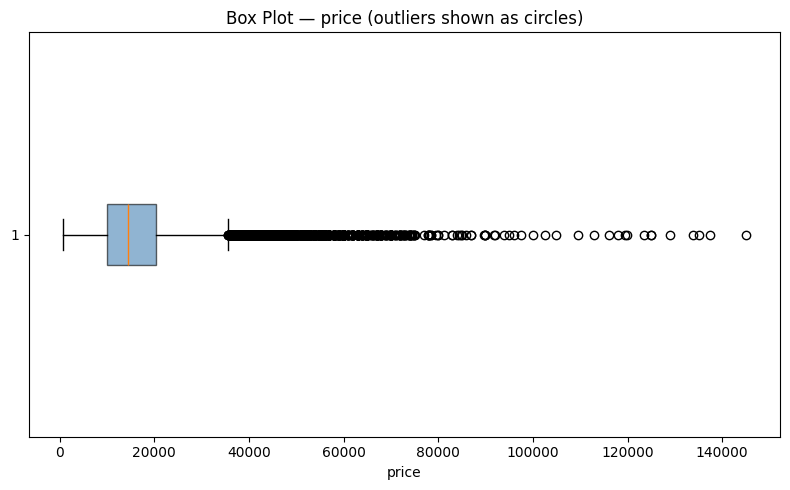

In [15]:
plt.figure(figsize=(8, 5))
plt.boxplot(train['price'], vert=False, patch_artist=True,
            boxprops=dict(facecolor='steelblue', alpha=0.6))
plt.title('Box Plot — price (outliers shown as circles)')
plt.xlabel('price')
plt.tight_layout()
plt.show()

# IQR method to handle outliers in price

In [16]:
Q1  = train_final['price'].quantile(0.25)
Q3  = train_final['price'].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
print(f"the prices between {lower:.0f} and {upper:.0f}")
print(f"Rows before: {len(train_final)}")
train_final = train_final[(train_final['price'] >= lower) & (train_final['price'] <= upper)]
print(f"Rows after: {len(train_final)}")

the prices between -5199 and 35595
Rows before: 55051
Rows after: 53016


## task 3 : create the 2 target variables 

### Regression Target

The regression target is the raw continuous `price` column. The model will learn to predict the exact market value of each car.

In [17]:
Y_Reg_target= df["price"]
print(Y_Reg_target.sample(5))
print('\n the regression target variable is price done successfully')

3871     32000.0
2769     14180.0
23060     5491.0
42442    13950.0
28233     7700.0
Name: price, dtype: float64

 the regression target variable is price done successfully


### Classification Target

To build a classifier, the continuous price is discretized into three named tiers based on the histogram distribution observed in Task 1.

**Threshold Justification:**

The histogram shows the majority of cars are priced between 10,000 and 20,000. Based on this distribution, three thresholds are defined:

| Tier | Condition |
|------|-----------|
| Cheap | price < 10,000 |
| Moderate | 10,000 <= price < 20,000 |
| Expensive | price >= 20,000 |

This partitioning produces reasonably balanced classes and reflects a natural boundary in the data rather than an arbitrary split.

In [18]:
def price_category(price):
    if price <10000:
        return "Cheap"
    elif 10000<=price <20000:
        return "Moderate"
    else:
        return "Expensive"
    

df["price_category"] = df["price"].apply(price_category)

print(df[["price_category" ,"price" ]].sample(10))

      price_category    price
5579       Expensive  20950.0
31460       Moderate  16495.0
5249       Expensive  52990.0
36986       Moderate  12000.0
60354      Expensive  21698.0
22441       Moderate  14000.0
68371          Cheap   7685.0
63829       Moderate  15850.0
19822       Moderate  12991.0
39870      Expensive  21650.0


In [19]:
print("Number of cars in each price category:")
print(df['price_category'].value_counts())

Number of cars in each price category:
price_category
Moderate     34452
Expensive    17599
Cheap        16763
Name: count, dtype: int64


# task 4 : Making the  model

In [20]:
X_train = train_final.drop(columns=['price'])
Y_train = train_final['price']

X_test  = test_final.drop(columns=['price'])
Y_test  = test_final['price']

# Train the model

In [ ]:
simple_model = LinearRegression()
simple_model.fit(X_train, Y_train)
y_pred = simple_model.predict(X_test)
comparison = pd.DataFrame({'Actual': Y_test, 'Predicted': y_pred})
print(comparison.head())

        Actual     Predicted
5929   24500.0  22902.571931
69096   6750.0   4618.117863
70208  13990.0  12560.818025
53601  17712.0  19347.243606
24421   7690.0  11743.854053


# mae, mse, rmse, r2

In [22]:
mae = mean_absolute_error(Y_test, y_pred)
mse = mean_squared_error(Y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, y_pred)
print(f"Mean Absolute Error: {mae:.2f}")
print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error: {rmse:.2f}")
print(f"R-squared: {r2:.2f}")

Mean Absolute Error: 2459.19
Mean Squared Error: 19279041.72
Root Mean Squared Error: 4390.79
R-squared: 0.77


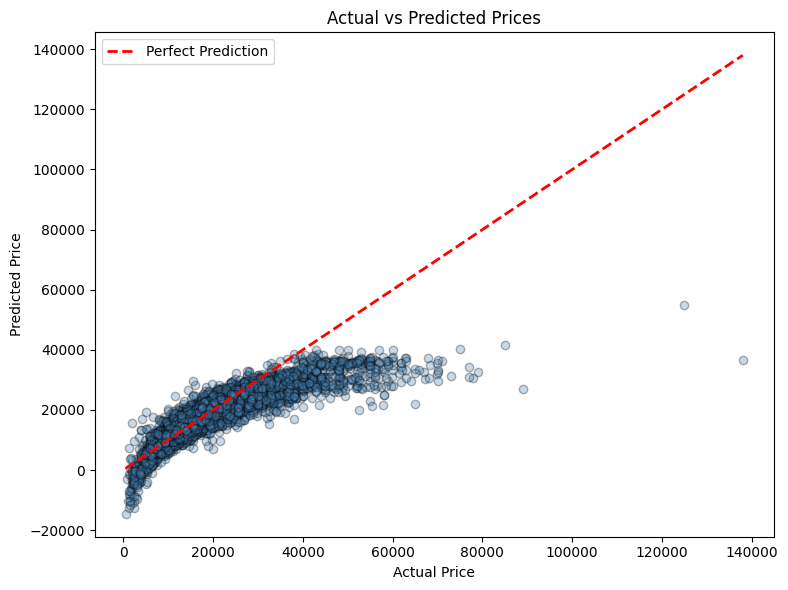

In [23]:
plt.figure(figsize=(8, 6))
plt.scatter(Y_test, y_pred, alpha=0.3, color='steelblue', edgecolor='k')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'r--',
         linewidth=2, label='Perfect Prediction')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Prices')
plt.legend()
plt.tight_layout()
plt.show()

# classification

In [24]:
y_train_cls = df.loc[train_final.index, 'price_category']
y_test_cls  = df.loc[test_final.index,  'price_category']

x_train_cls = train_final.drop(columns=['price'])
x_test_cls  = test_final.drop(columns=['price'])

print("Train class distribution:")
print(y_train_cls.value_counts())
print("\nTest class distribution:")
print(y_test_cls.value_counts())

Train class distribution:
price_category
Moderate     27521
Cheap        13478
Expensive    12017
Name: count, dtype: int64

Test class distribution:
price_category
Moderate     6931
Expensive    3547
Cheap        3285
Name: count, dtype: int64


In [25]:
param_grid = {'n_neighbors': [3, 5, 7, 9, 11, 13], 'metric': ['euclidean', 'manhattan']}
knn = KNeighborsClassifier()
grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy')
grid_search.fit(x_train_cls, y_train_cls)
print(f"Best K         : {grid_search.best_params_['n_neighbors']}")
print(f"Best metric    : {grid_search.best_params_['metric']}")
print(f"Best CV score  : {grid_search.best_score_:.4f}")

Best K         : 5
Best metric    : manhattan
Best CV score  : 0.8790


# Best model and predection

In [26]:
best_knn = grid_search.best_estimator_

y_pred_cls = best_knn.predict(x_test_cls)

print("Sample predictions vs actual:")
import pandas as pd
print(pd.DataFrame({'Actual': y_test_cls.values[:10], 'Predicted': y_pred_cls[:10]}))

Sample predictions vs actual:
      Actual  Predicted
0  Expensive  Expensive
1      Cheap      Cheap
2   Moderate   Moderate
3   Moderate   Moderate
4      Cheap      Cheap
5   Moderate   Moderate
6   Moderate   Moderate
7   Moderate   Moderate
8   Moderate      Cheap
9   Moderate   Moderate


# Accuracy and precision and recall and f1

In [27]:
acc = accuracy_score(y_test_cls, y_pred_cls)
print(f"Accuracy: {acc:.4f}")
print()

print("Classification Report:")
print(classification_report(y_test_cls, y_pred_cls))

Accuracy: 0.8853

Classification Report:
              precision    recall  f1-score   support

       Cheap       0.89      0.86      0.87      3285
   Expensive       0.90      0.89      0.89      3547
    Moderate       0.88      0.90      0.89      6931

    accuracy                           0.89     13763
   macro avg       0.89      0.88      0.88     13763
weighted avg       0.89      0.89      0.89     13763



# Confusion matrix

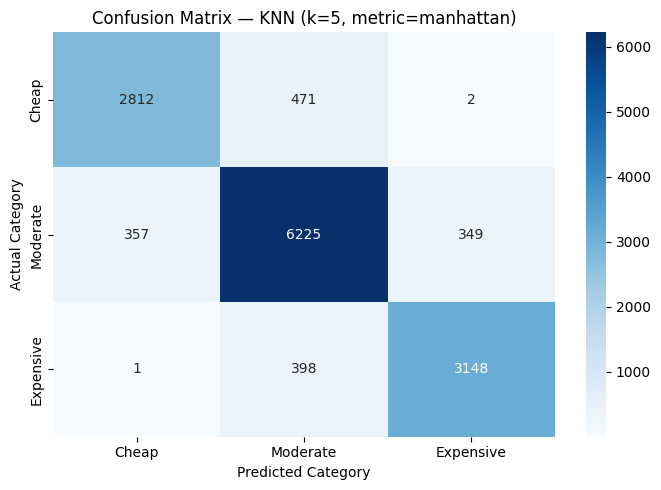

In [28]:
labels = ['Cheap', 'Moderate', 'Expensive']

cm = confusion_matrix(y_test_cls, y_pred_cls, labels=labels)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,          
    fmt='d',             
    cmap='Blues',        
    xticklabels=labels,
    yticklabels=labels
)
plt.title(f'Confusion Matrix — KNN (k={grid_search.best_params_["n_neighbors"]}, metric={grid_search.best_params_["metric"]})')
plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.tight_layout()
plt.show()

# Task 7: Visualization

# Correlation Heatmap

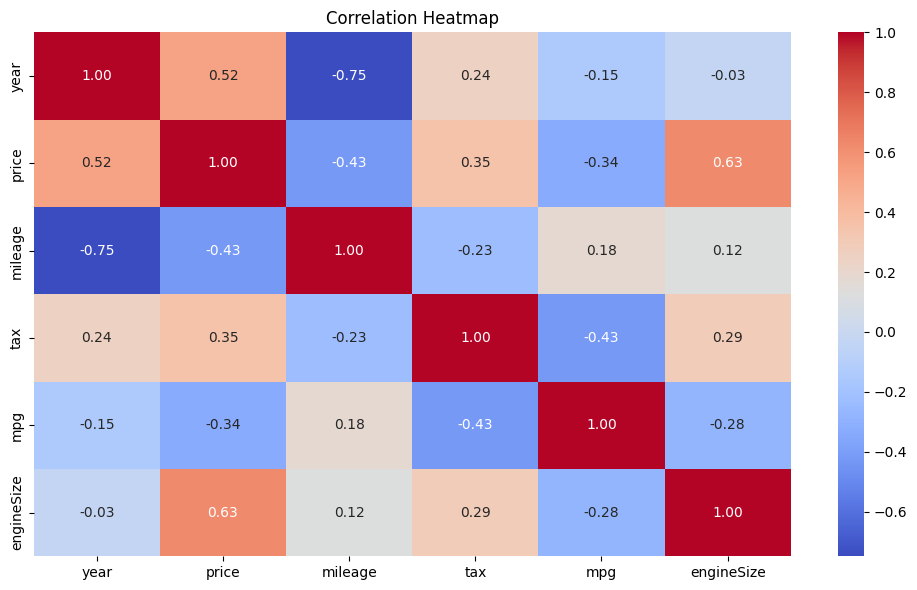

In [29]:
df_corr = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 6))
sns.heatmap(df_corr.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Age vs Price Relationship

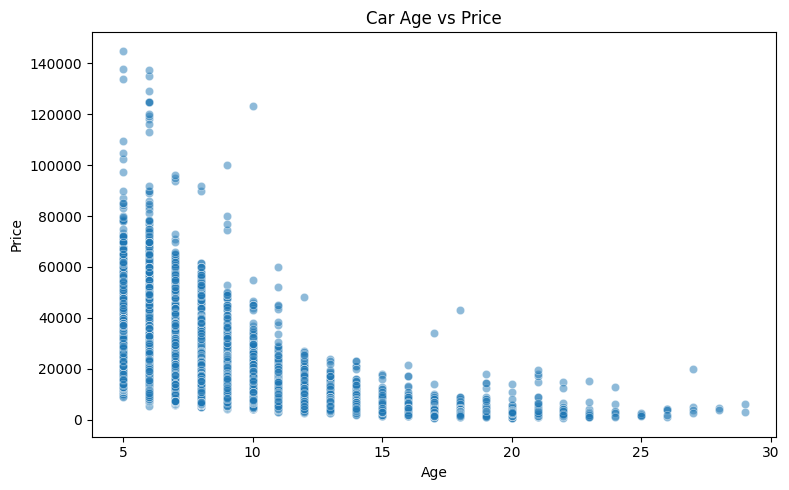

In [30]:
df['age'] = 2025 - df['year']

plt.figure(figsize=(8,5))
sns.scatterplot(x='age', y='price', data=df, alpha=0.5)
plt.title("Car Age vs Price")
plt.xlabel("Age")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

# Price by Fuel Type


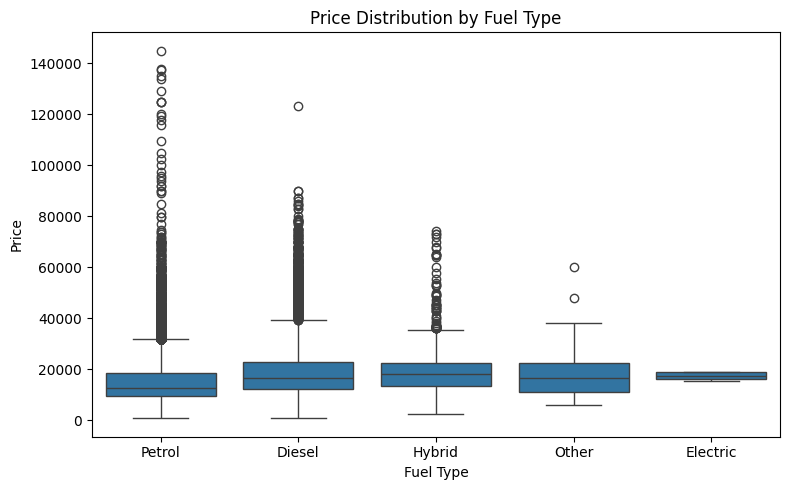

In [31]:
plt.figure(figsize=(8,5))
sns.boxplot(x='fuelType', y='price', data=df)
plt.title("Price Distribution by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

# Average Price by Car Make

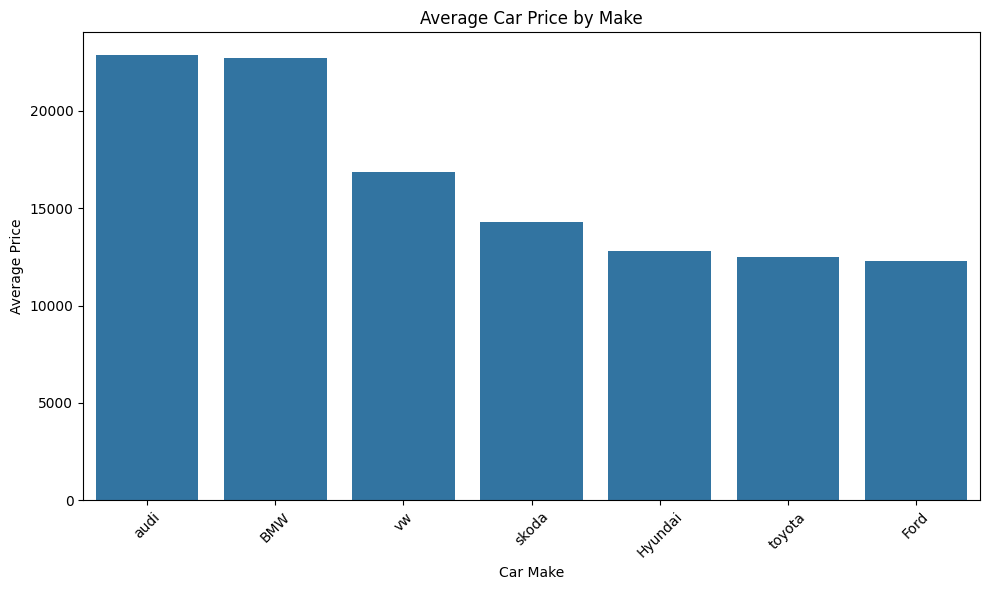

In [32]:
plt.figure(figsize=(10,6))

avg_price_by_make = df.groupby('Make')['price'].mean().sort_values(ascending=False)

sns.barplot(x=avg_price_by_make.index, y=avg_price_by_make.values)

plt.title("Average Car Price by Make")
plt.xlabel("Car Make")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Task 6: Analysis and Discussion
6.1 Model Comparison
Which model performed better, and what does "better" mean in each context?
Each model has its own definition of "better":

For Linear Regression, better means a high R² (close to 1) and low RMSE/MAE — meaning predictions are close to the actual prices.
For KNN Classifier, better means high Accuracy, Precision, Recall, and F1-score — meaning the model correctly assigns cars to the right price category.

You can't directly compare the two since they solve different problems. Regression is harder to "do well" on because it must predict an exact number, while classification only needs to get the right bucket.


Is classification easier than regression on this dataset? Why or why not?
Yes, classification is generally easier here. 
Regression must predict an exact price (e.g., £13,472), which is very sensitive to noise in the data. 
Classification only needs to decide "Cheap, Moderate, or Expensive," which tolerates more error — a prediction of £9,800 instead of £10,200 is wrong for regression, but both still land in the same category. 
So classification naturally has more room for error and still be considered "correct."

Does converting price into categories lose important information?
Yes, it does. Two cars priced at £9,999 and £10,001 are nearly identical in value,
but after categorization they fall into completely different classes (Cheap vs. Moderate). This is called the boundary problem. 
Any fine-grained price difference within a category is completely invisible to the classifier. If the goal is to estimate actual value (e.g., for insurance or resale), 
regression is far more informative. Classification is only appropriate when the exact price doesn't matter, just the tier.

# 6.2 Sensitivity Analysis

What happens if you remove the most correlated feature? Does performance drop a lot?
The most correlated numerical feature with price is likely mileage or age (year). 
Removing it would cause a noticeable drop in R² for the regression model because that feature carries the most predictive signal. 
However, the drop may not be catastrophic because other correlated features (engine size, fuel type, make) partially compensate. 
The model becomes less accurate but doesn't completely fail. This shows the model has some redundancy in its features.

Try running KNN without scaling — how much does performance change?
Performance drops significantly without scaling. 
KNN is a distance-based algorithm — it measures how "close" two cars are in feature space. Without scaling, features with large numerical ranges (like mileage, which can be in the hundreds of thousands) completely dominate the distance calculation over features with small ranges (like age, which is 1–20). 
This makes the model effectively ignore smaller-range features, leading to worse and biased predictions. This is why StandardScaler is essential for KNN.

Try a different threshold for your price categories — does KNN accuracy change significantly?
Yes, it can change noticeably. 
The original thresholds (Cheap < £10k, Moderate £10k–£20k, Expensive > £20k) were chosen based on the histogram distribution, 
which means the classes are reasonably balanced. 
If you shift the thresholds (e.g., Cheap < £7k, Moderate £7k–£15k), 
the class sizes become more imbalanced — one category might have very few examples, making it harder for KNN to learn its boundary. 
Imbalanced classes generally hurt accuracy, especially for the minority class. 
This confirms that threshold choice directly affects model performance and should always be justified by the data distribution.

---

# Assignment 2 — FIFA Players Performance Analysis

**Dataset:** `Fifa.csv`

This assignment applies machine learning to FIFA player data. The goal is to predict a player's market value through regression and classify players into performance tiers through multi-class classification. All models are validated with cross-validation.


#  Machine Learning Assignment 2 — FIFA Players Performance Analysis

## Overview
This notebook solves three machine learning problems using the **FIFA Players Dataset**:
- **Regression** — Predict a player's market value (Value Per M$)
- **Classification** — Group players into performance tiers: Low, Medium, High, Elite
- **Model Validation** — Evaluate all models rigorously using Cross-Validation

### Tasks at a Glance
| Task | Description |
|------|-------------|
| 1 | Exploratory Data Analysis (EDA) |
| 2 | Data Preprocessing |
| 3 | Classification Target Creation |
| 4 | Polynomial Regression + Regularization |
| 5 | Logistic Regression + Regularization |
| 6 | Naïve Bayes Classification |
| 7 | Cross-Validation |
| 8 | Analysis & Discussion |

---

#  Task 1: Exploratory Data Analysis (EDA)

## What We Do Here
Before building any model, we explore the dataset to understand its structure, distributions, and relationships.

**Questions answered in this section:**
1. Are there missing values? How many and in which columns?
2. What does the distribution of `Value Per M$` look like — is it normal or skewed?
3. Which features are most correlated with `Value Per M$`?
4. What is the average `Overall_Rating` per Position?

We first load the dataset and inspect its shape, column types, and summary statistics.

In [33]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (OrdinalEncoder, OneHotEncoder,
                                   StandardScaler, MinMaxScaler,
                                   RobustScaler, PowerTransformer)
from sklearn.naive_bayes import GaussianNB, BernoulliNB, ComplementNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

In [34]:
Data = pd.read_csv("Fifa.csv")

In [35]:
print(f"Number of rows is {Data.shape[0]} \n Number of columns is {Data.shape[1]}")

Number of rows is 19667 
 Number of columns is 9


In [36]:
Num_col=Data.select_dtypes(include=np.number).columns.to_list()
categorical_cols = Data.select_dtypes(include='object').columns.tolist()
print("Numerical Data is : " , Num_col)
print("Categorical  Data is : " , categorical_cols)

Numerical Data is :  ['Age', 'Overall_Rating', 'Future Potential', 'Value Per M$', 'Total_Stats Score']
Categorical  Data is :  ['Name', 'Country', 'Position', 'Team']


In [37]:
print("No, there aren't missing values :\n",Data.isnull().sum())

No, there aren't missing values :
 Name                 0
Country              0
Position             0
Age                  0
Overall_Rating       0
Future Potential     0
Team                 0
Value Per M$         0
Total_Stats Score    0
dtype: int64


In [38]:
print(f"Number of Duplicated is : {Data.duplicated().sum()}")

Number of Duplicated is : 0


In [39]:
print(Data.describe())

                Age  Overall_Rating  Future Potential  Value Per M$  \
count  19667.000000    19667.000000      19667.000000  19667.000000   
mean      22.990034       63.225403         70.658718      2.514639   
std        4.692410        7.812716          6.489551      7.256974   
min       15.000000       36.000000         46.000000      0.000000   
25%       19.000000       58.000000         66.000000      0.325000   
50%       22.000000       63.000000         70.000000      0.675000   
75%       26.000000       68.000000         75.000000      1.600000   
max       44.000000       91.000000         95.000000    190.500000   

       Total_Stats Score  
count       19667.000000  
mean         1534.513907  
std           283.248088  
min           416.000000  
25%          1388.000000  
50%          1549.000000  
75%          1720.000000  
max          2324.000000  


### Distribution of Value Per M$
We plot a histogram with a KDE curve to visualize how player market values are distributed.

> **Expected insight:** Most players have low market values, with a few superstars driving a long right tail — this is a **right-skewed** distribution.

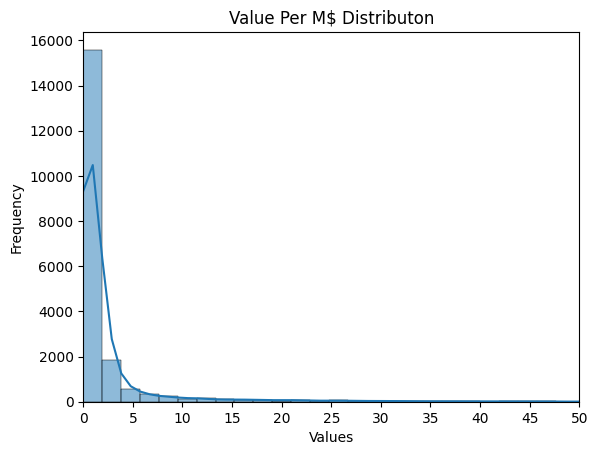

In [40]:
sns.histplot(Data['Value Per M$'], bins=100, kde=True)
plt.title('Value Per M$ Distributon')
plt.xlabel('Values')
plt.ylabel('Frequency')

plt.xlim(0, 50)

plt.xticks(range(0,51,5))

plt.show()

In [41]:
skewness = Data['Value Per M$'].skew()
print("Skewness:", skewness)

Skewness: 7.983215201865151


### Feature Correlation with Value Per M$
We compute the Pearson correlation matrix and display a heatmap filtered to show only correlations with the target variable.

> **Expected insight:** `Overall_Rating` and `Future Potential` are the strongest predictors of market value, while `Age` tends to have a weaker or inverse relationship for older players.

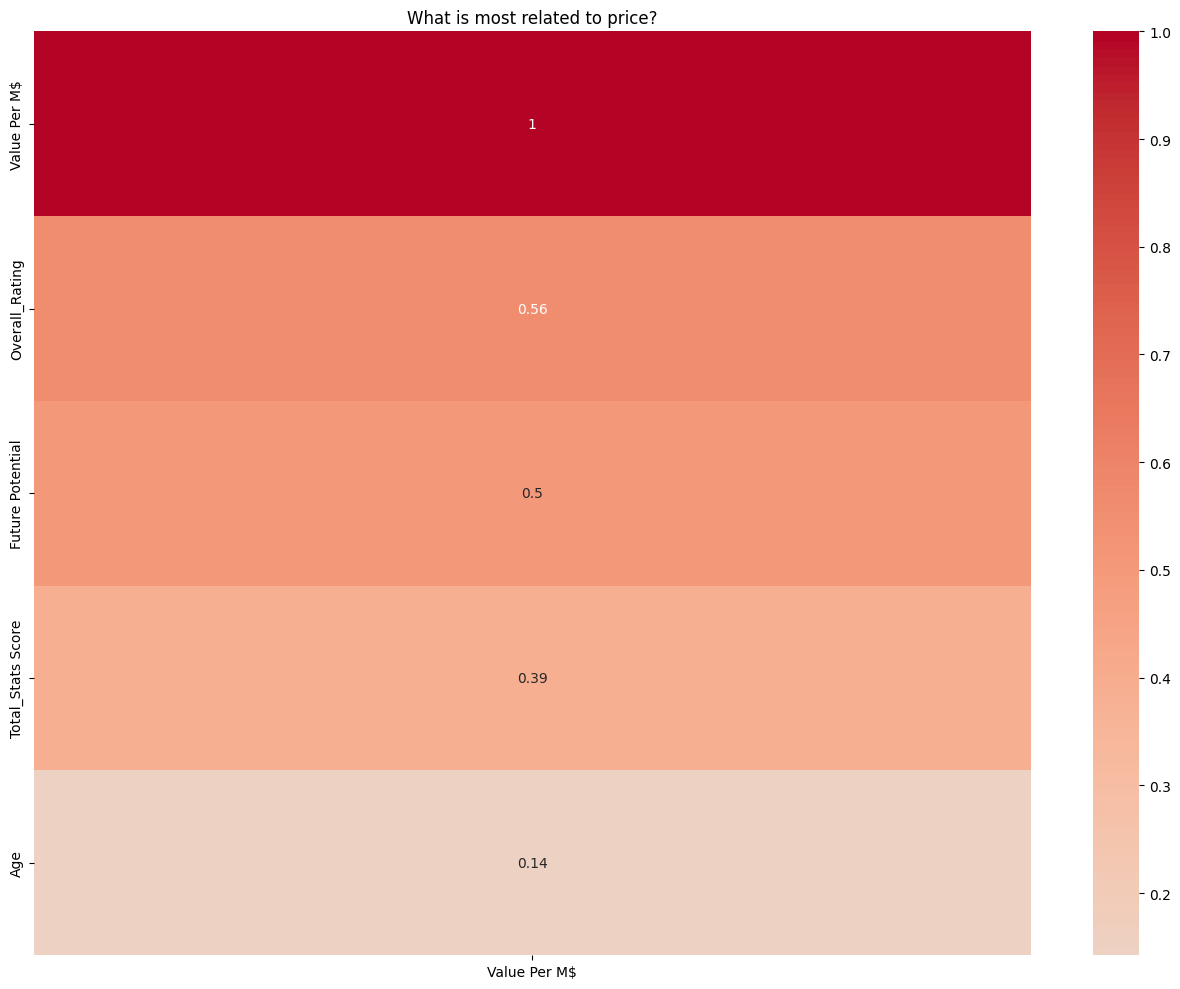

In [42]:
corr = Data.select_dtypes(include=np.number).corr()

plt.figure(figsize=(13, 10))
sns.heatmap(Data.corr(numeric_only=True)[["Value Per M$"]].sort_values(by='Value Per M$', ascending=False),
            annot=True, cmap='coolwarm', center=0)
plt.title('What is most related to price?')
plt.tight_layout()
plt.show()

### Average Overall Rating per Position
We group players by their field position and compute the mean `Overall_Rating` for each.

> **Expected insight:** Goalkeepers (GK) and central defenders tend to have different rating distributions than attackers.

In [43]:
avg_rating_per_position = Data.groupby('Position')['Overall_Rating'].mean().sort_values(ascending=False)

print(avg_rating_per_position)

Position
SW     75.000000
RF     75.000000
CF     66.042857
LW     64.345979
CDM    64.234168
LM     64.172009
RWB    64.063973
LWB    64.043333
RM     63.907731
RW     63.718529
CAM    63.679709
CB     63.544448
LB     63.276794
ST     63.087505
RB     62.863636
CM     62.511767
GK     60.987288
Name: Overall_Rating, dtype: float64


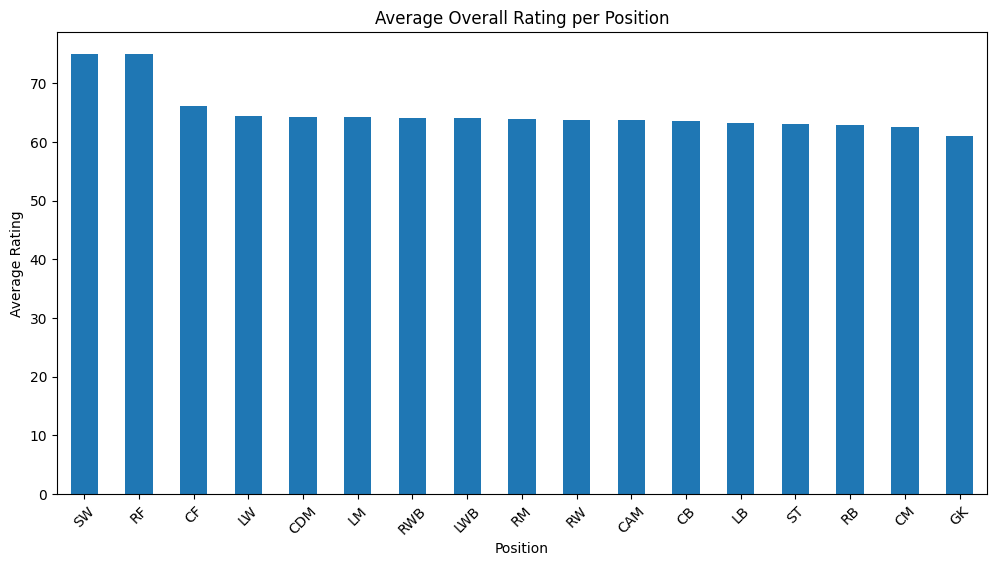

In [44]:
avg_rating_per_position.plot(kind='bar', figsize=(12,6))
plt.title('Average Overall Rating per Position')
plt.xlabel('Position')
plt.ylabel('Average Rating')
plt.xticks(rotation=45)
plt.show()

#  Task 2: Data Preprocessing

## What We Do Here
We apply a consistent preprocessing pipeline so that all models receive clean, normalized data.

**Steps performed:**
1. **Drop irrelevant columns** — `Name` and `Team` are identifiers, not features
2. **Train/Test Split (80/20)** — All preprocessing is fit ONLY on train data to prevent data leakage
3. **Outlier Detection & Removal** — Visualize with boxplot; remove extreme values in `Value Per M$`
4. **Feature Scaling** — Apply `StandardScaler` to numerical columns
5. **Categorical Encoding** — Apply `OneHotEncoder` to `Country` and `Position`

>  **Important:** The scaler and encoder are fit on the **training set only**, then applied to the test set. This prevents data leakage.

In [45]:
Data = Data.drop(columns=["Name", "Team"])
categorical_cols = Data.select_dtypes(include='object').columns.tolist()

In [46]:
train , test = train_test_split(Data,test_size=0.2,random_state=1)
print(f'Train: {train.shape}  |  Test: {test.shape}')

Train: (15733, 7)  |  Test: (3934, 7)


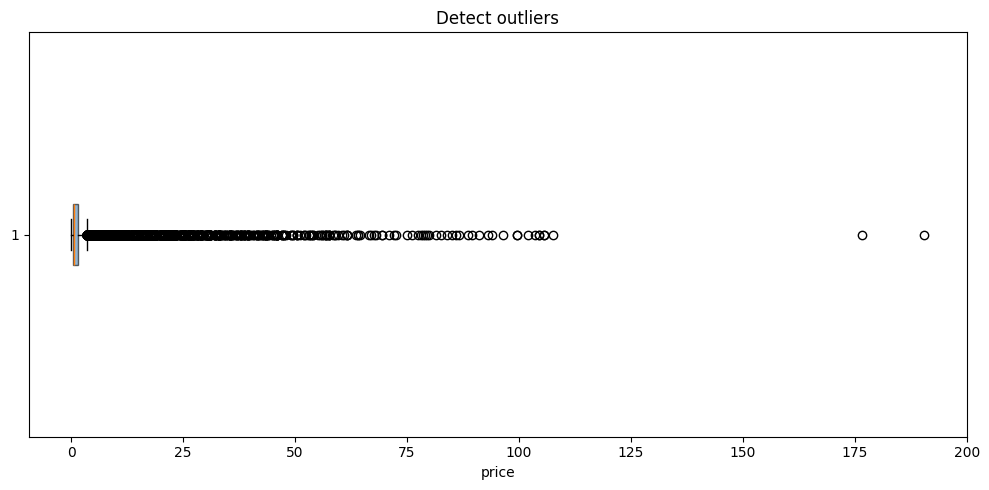

In [47]:
plt.figure(figsize=(10, 5))
plt.boxplot(train['Value Per M$'], vert=False, patch_artist=True,
            boxprops=dict(facecolor='steelblue', alpha=0.6))
plt.title('Detect outliers')
plt.xlabel('price')
plt.tight_layout()
plt.show()

In [48]:
train = train[train['Value Per M$'] < 150]

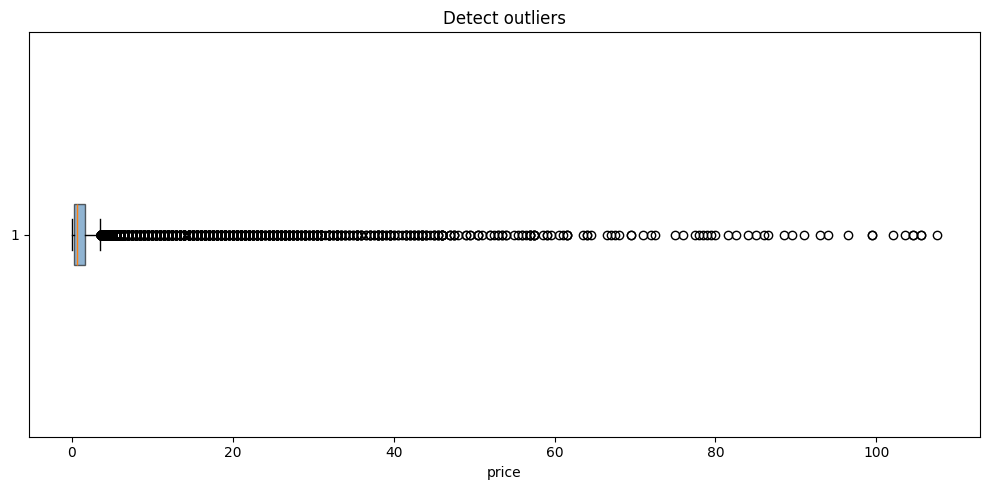

In [49]:
plt.figure(figsize=(10, 5))
plt.boxplot(train['Value Per M$'], vert=False, patch_artist=True,
            boxprops=dict(facecolor='steelblue', alpha=0.6))
plt.title('Detect outliers')
plt.xlabel('price')
plt.tight_layout()
plt.show()

In [50]:
Num_col = [col for col in train.select_dtypes(include='number').columns if col != 'Value Per M$']
ss = StandardScaler()
train[Num_col]=ss.fit_transform(train[Num_col])
test[Num_col]=ss.transform(test[Num_col])

In [51]:
enc =OneHotEncoder(handle_unknown="ignore", sparse_output=False)
train_enc=enc.fit_transform(train[categorical_cols])
test_enc=enc.transform(test[categorical_cols])
col_names=enc.get_feature_names_out(categorical_cols)

In [52]:
train_one = pd.DataFrame(
    train_enc,
    columns=col_names,
    index=train.index
)
test_one = pd.DataFrame(
    test_enc,
    columns=col_names,
    index=test.index
)

In [53]:
train = train.drop(columns=categorical_cols)
test  = test.drop(columns=categorical_cols)


train = pd.concat([train, train_one], axis=1)
test = pd.concat([test, test_one], axis = 1)

In [54]:
print(f'Number of rows is {train.shape[0]} \n Number of columns is {train.shape[1]}')
print(train.head())

Number of rows is 15731 
 Number of columns is 180
            Age  Overall_Rating  Future Potential  Value Per M$  \
15046  0.855288        0.864013          0.206144          1.70   
15914 -0.211855       -0.413819         -0.256570          0.55   
18918 -0.425284       -0.158253         -0.102332          0.90   
18080  0.001574       -0.669386         -0.873522          0.35   
951   -0.425284        0.991796          2.211237          4.60   

       Total_Stats Score  Country_Albania  Country_Algeria  Country_Angola  \
15046           0.024006              0.0              0.0             0.0   
15914          -0.071274              0.0              0.0             0.0   
18918          -0.420633              0.0              0.0             0.0   
18080          -2.446209              0.0              0.0             0.0   
951             0.570982              0.0              0.0             0.0   

       Country_Argentina  Country_Armenia  ...  Position_LM  Position_LW  \
1

#  Task 3: Create Classification Target

## What We Do Here
We convert the regression target (`Overall_Rating`) into a **4-class classification problem** by binning players into performance tiers.

**Threshold Strategy — Quartile-Based:**
We use the 25th, 50th, and 75th percentiles of `Overall_Rating` to define thresholds:

| Tier | Condition |
|------|-----------|
| **Low** | Overall_Rating ≤ Q1 (25th percentile) |
| **Medium** | Q1 < Overall_Rating ≤ Q2 (50th percentile) |
| **High** | Q2 < Overall_Rating ≤ Q3 (75th percentile) |
| **Elite** | Overall_Rating > Q3 (75th percentile) |

**Justification:** Using quartiles guarantees that each class contains approximately 25% of players, producing a **balanced dataset** — which is ideal for classification.

We also add a **bar chart** of class distribution to visually confirm balance.

In [55]:
q1 = train['Overall_Rating'].quantile(0.25)
q2 = train['Overall_Rating'].quantile(0.50)
q3 = train['Overall_Rating'].quantile(0.75)

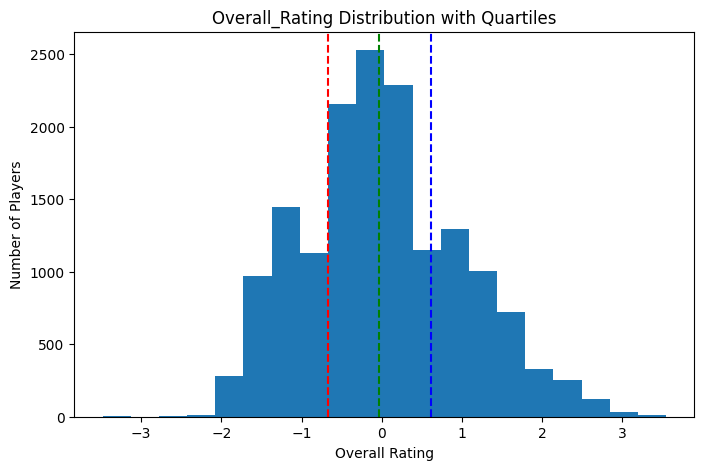

In [56]:
q1 = train['Overall_Rating'].quantile(0.25)
q2 = train['Overall_Rating'].quantile(0.50)
q3 = train['Overall_Rating'].quantile(0.75)

plt.figure(figsize=(8,5))
plt.hist(train['Overall_Rating'], bins=20)

plt.axvline(q1, color='r', linestyle='--')
plt.axvline(q2, color='g', linestyle='--')
plt.axvline(q3, color='b', linestyle='--')

plt.title('Overall_Rating Distribution with Quartiles')
plt.xlabel('Overall Rating')
plt.ylabel('Number of Players')
plt.show()

In [57]:
def performance_category(x):
    if x <= q1:
        return "Low"
    elif x <= q2:
        return "Medium"
    elif x <= q3:
        return "High"
    else:
        return "Elite"

In [58]:
train['Performance_Class'] = train['Overall_Rating'].apply(performance_category)
test['Performance_Class'] = test['Overall_Rating'].apply(performance_category)

In [59]:
train['Performance_Class'].value_counts()

Performance_Class
Low       4467
Medium    4062
Elite     3766
High      3436
Name: count, dtype: int64

## Class Distribution Analysis

The quartile-based binning strategy is designed to produce an approximately balanced dataset. The pie chart below confirms this — each tier captures roughly 25% of the training players, which is ideal for classification as it prevents the model from being biased toward any majority class.

<Axes: >

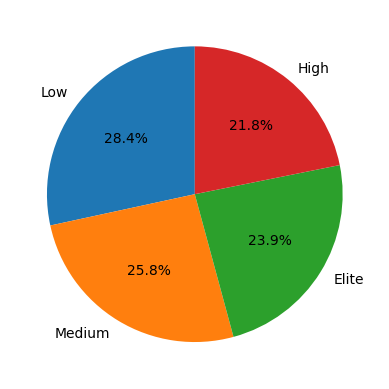

In [60]:
train['Performance_Class'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    ylabel=''
)

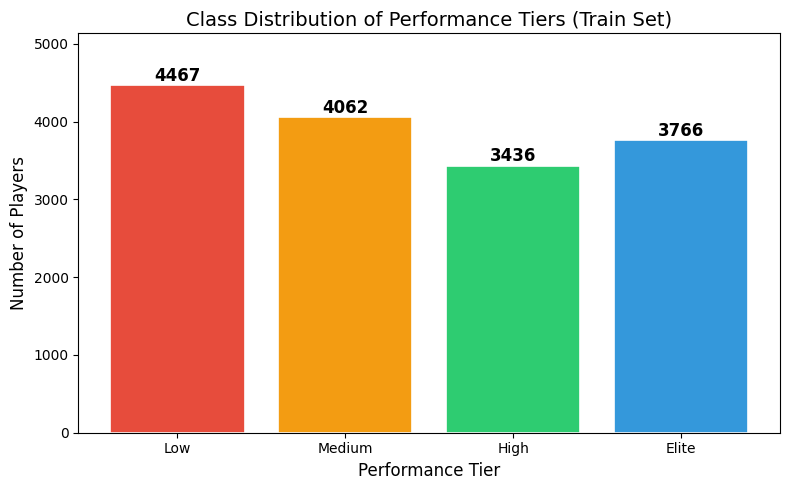

Class Counts:
  Low     : 4467 players
  Medium  : 4062 players
  High    : 3436 players
  Elite   : 3766 players

Dataset is BALANCED (max/min ratio = 1.30)


In [61]:
plt.figure(figsize=(8, 5))
class_order = ['Low', 'Medium', 'High', 'Elite']
counts = train['Performance_Class'].value_counts().reindex(class_order)

bars = plt.bar(class_order, counts.values,
               color=['#e74c3c', '#f39c12', '#2ecc71', '#3498db'],
               edgecolor='white', linewidth=1.2)

for bar, val in zip(bars, counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
             str(val), ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.title('Class Distribution of Performance Tiers (Train Set)', fontsize=14)
plt.xlabel('Performance Tier', fontsize=12)
plt.ylabel('Number of Players', fontsize=12)
plt.ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()

print("Class Counts:")
for cls in class_order:
    print(f"  {cls:8s}: {counts[cls]} players")
print(f"\nDataset is {'BALANCED' if counts.max() / counts.min() < 1.5 else 'IMBALANCED'} "
      f"(max/min ratio = {counts.max()/counts.min():.2f})")

#  Task 4: Model 1 — Polynomial Regression

## What We Do Here
We train regression models to **predict player market value** (`Value Per M$`).

**Steps:**
- **Part A:** Baseline Linear Regression (degree=1) — evaluate MAE, MSE, RMSE, R²
- **Part B:** Expand features using `PolynomialFeatures` for degrees 1–4; compare Train vs Test R²
- **Part C:** Apply Ridge (L2) and Lasso (L1) regularization on the best degree; sweep alpha values
- **Part D:** Compare Ridge vs Lasso and inspect which features Lasso zeroes out

> **Note:** PolynomialFeatures is applied **only to numerical features** to avoid an explosion in the feature space from one-hot encoded binary columns.

In [62]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

reg_feature_cols = [col for col in train.columns if col not in ['Value Per M$', 'Performance_Class']]

X_train_reg = train[reg_feature_cols]
y_train_reg = train['Value Per M$']

X_test_reg = test[reg_feature_cols]
y_test_reg = test['Value Per M$']

lr_base = LinearRegression()
lr_base.fit(X_train_reg, y_train_reg)

y_train_pred = lr_base.predict(X_train_reg)
y_test_pred  = lr_base.predict(X_test_reg)

def regression_metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_true, y_pred)
    print(f"  {label}:  MAE={mae:.3f}  MSE={mse:.3f}  RMSE={rmse:.3f}  R²={r2:.4f}")
    return r2

print("=== Baseline Linear Regression ===")
train_r2 = regression_metrics(y_train_reg, y_train_pred, "Train")
test_r2  = regression_metrics(y_test_reg,  y_test_pred,  "Test ")

=== Baseline Linear Regression ===
  Train:  MAE=2.885  MSE=29.493  RMSE=5.431  R²=0.4128
  Test :  MAE=2.911  MSE=28.342  RMSE=5.324  R²=0.3805


## Part B: Polynomial Degrees 1–4 — Train vs Test R²

Degree 1:  Train R²=0.3711  |  Test R²=0.3552  |  Gap=0.0159
Degree 2:  Train R²=0.7504  |  Test R²=0.7383  |  Gap=0.0121
Degree 3:  Train R²=0.9318  |  Test R²=0.9332  |  Gap=-0.0015
Degree 4:  Train R²=0.9735  |  Test R²=0.9751  |  Gap=-0.0017


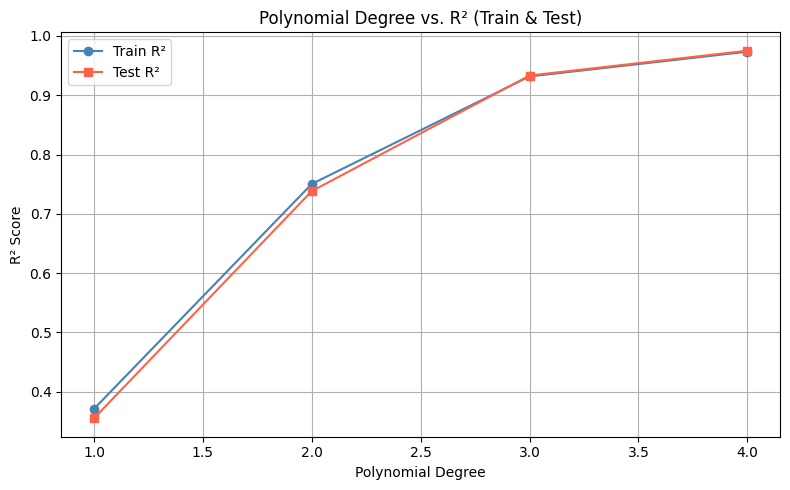


Best degree for generalization: 4  (Test R²=0.9751)


In [63]:
num_reg_cols = [col for col in X_train_reg.columns
                if X_train_reg[col].nunique() > 2]   # exclude OHE binary cols

X_train_num = X_train_reg[num_reg_cols]
X_test_num  = X_test_reg[num_reg_cols]

degrees = [1, 2, 3, 4]
train_r2_list = []
test_r2_list  = []

for deg in degrees:
    pipe = Pipeline([
        ("poly", PolynomialFeatures(degree=deg, include_bias=False)),
        ("lr",   LinearRegression())
    ])
    pipe.fit(X_train_num, y_train_reg)

    tr2 = r2_score(y_train_reg, pipe.predict(X_train_num))
    te2 = r2_score(y_test_reg,  pipe.predict(X_test_num))
    train_r2_list.append(tr2)
    test_r2_list.append(te2)
    print(f"Degree {deg}:  Train R²={tr2:.4f}  |  Test R²={te2:.4f}  |  Gap={tr2-te2:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(degrees, train_r2_list, 'o-', label='Train R²', color='steelblue')
plt.plot(degrees, test_r2_list,  's-', label='Test R²',  color='tomato')
plt.xlabel('Polynomial Degree')
plt.ylabel('R² Score')
plt.title('Polynomial Degree vs. R² (Train & Test)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

best_degree = degrees[test_r2_list.index(max(test_r2_list))]
print(f"\nBest degree for generalization: {best_degree}  (Test R²={max(test_r2_list):.4f})")

## Part C: Regularization — Ridge & Lasso

c:\Users\Asus - TUF\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.450e+03, tolerance: 7.901e+01
  model = cd_fast.enet_coordinate_descent(
c:\Users\Asus - TUF\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.633e+03, tolerance: 7.901e+01
  model = cd_fast.enet_coordinate_descent(
c:\Users\Asus - TUF\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations

Best Ridge alpha: 8.2864  |  Min Test RMSE: 1.0577
Best Lasso alpha: 0.0010  |  Min Test RMSE: 1.0602


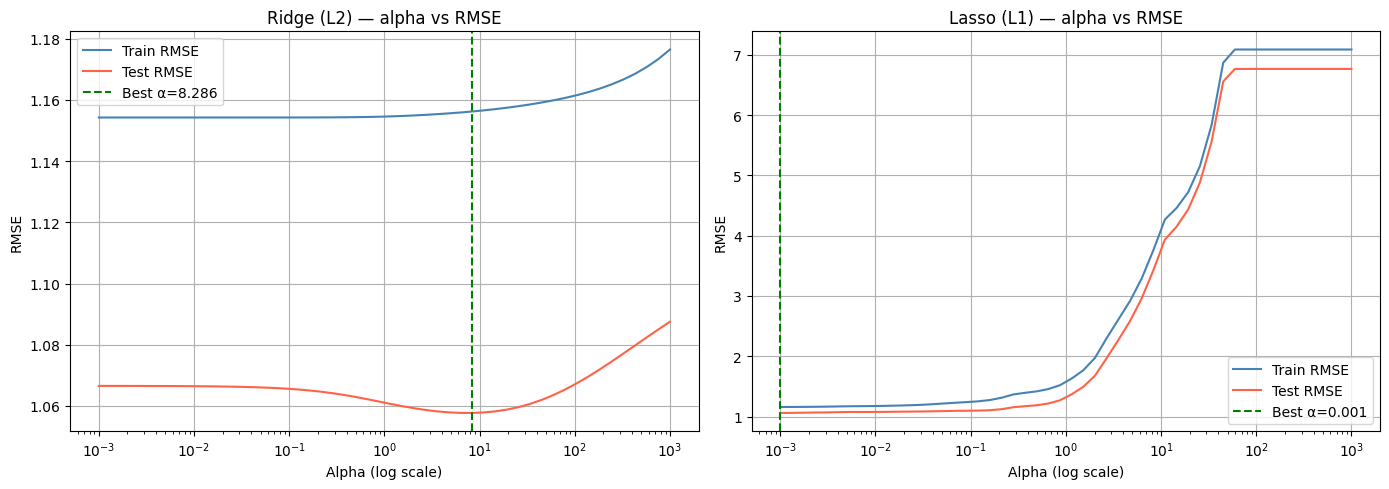

In [64]:
from sklearn.preprocessing import PolynomialFeatures

best_deg = best_degree
poly = PolynomialFeatures(degree=best_deg, include_bias=False)
X_train_poly = poly.fit_transform(X_train_num)
X_test_poly  = poly.transform(X_test_num)

alphas = np.logspace(-3, 3, 50)

ridge_train_rmse = []
ridge_test_rmse  = []
lasso_train_rmse = []
lasso_test_rmse  = []

for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_poly, y_train_reg)
    ridge_train_rmse.append(np.sqrt(mean_squared_error(y_train_reg, ridge.predict(X_train_poly))))
    ridge_test_rmse.append( np.sqrt(mean_squared_error(y_test_reg,  ridge.predict(X_test_poly))))

    lasso = Lasso(alpha=alpha, max_iter=5000)
    lasso.fit(X_train_poly, y_train_reg)
    lasso_train_rmse.append(np.sqrt(mean_squared_error(y_train_reg, lasso.predict(X_train_poly))))
    lasso_test_rmse.append( np.sqrt(mean_squared_error(y_test_reg,  lasso.predict(X_test_poly))))

best_ridge_alpha = alphas[np.argmin(ridge_test_rmse)]
best_lasso_alpha = alphas[np.argmin(lasso_test_rmse)]
print(f"Best Ridge alpha: {best_ridge_alpha:.4f}  |  Min Test RMSE: {min(ridge_test_rmse):.4f}")
print(f"Best Lasso alpha: {best_lasso_alpha:.4f}  |  Min Test RMSE: {min(lasso_test_rmse):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].semilogx(alphas, ridge_train_rmse, label='Train RMSE', color='steelblue')
axes[0].semilogx(alphas, ridge_test_rmse,  label='Test RMSE',  color='tomato')
axes[0].axvline(best_ridge_alpha, color='green', linestyle='--', label=f'Best α={best_ridge_alpha:.3f}')
axes[0].set_title('Ridge (L2) — alpha vs RMSE')
axes[0].set_xlabel('Alpha (log scale)')
axes[0].set_ylabel('RMSE')
axes[0].legend()
axes[0].grid(True)

axes[1].semilogx(alphas, lasso_train_rmse, label='Train RMSE', color='steelblue')
axes[1].semilogx(alphas, lasso_test_rmse,  label='Test RMSE',  color='tomato')
axes[1].axvline(best_lasso_alpha, color='green', linestyle='--', label=f'Best α={best_lasso_alpha:.3f}')
axes[1].set_title('Lasso (L1) — alpha vs RMSE')
axes[1].set_xlabel('Alpha (log scale)')
axes[1].set_ylabel('RMSE')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Part D: Ridge vs Lasso — Zero Coefficients (Lasso Feature Selection)

In [65]:
ridge_best = Ridge(alpha=best_ridge_alpha)
ridge_best.fit(X_train_poly, y_train_reg)
ridge_test_pred = ridge_best.predict(X_test_poly)

lasso_best = Lasso(alpha=best_lasso_alpha, max_iter=5000)
lasso_best.fit(X_train_poly, y_train_reg)
lasso_test_pred = lasso_best.predict(X_test_poly)

print("=== Final Comparison at Best Alpha ===")
print(f"Ridge  — Test RMSE: {np.sqrt(mean_squared_error(y_test_reg, ridge_test_pred)):.4f}"
      f"  R²: {r2_score(y_test_reg, ridge_test_pred):.4f}")
print(f"Lasso  — Test RMSE: {np.sqrt(mean_squared_error(y_test_reg, lasso_test_pred)):.4f}"
      f"  R²: {r2_score(y_test_reg, lasso_test_pred):.4f}")

feature_names = poly.get_feature_names_out(num_reg_cols)
zeroed = feature_names[lasso_best.coef_ == 0]
nonzero = feature_names[lasso_best.coef_ != 0]

print(f"\nLasso zeroed out {len(zeroed)} / {len(feature_names)} features:")
print("  Zeroed features:", list(zeroed)[:15], "..." if len(zeroed) > 15 else "")
print(f"  Kept {len(nonzero)} features — Lasso performs automatic feature selection.")

=== Final Comparison at Best Alpha ===
Ridge  — Test RMSE: 1.0577  R²: 0.9755
Lasso  — Test RMSE: 1.0602  R²: 0.9754

Lasso zeroed out 8 / 69 features:
  Zeroed features: ['Age Future Potential', 'Overall_Rating Total_Stats Score', 'Age Overall_Rating Total_Stats Score', 'Age Future Potential Total_Stats Score', 'Future Potential Total_Stats Score^2', 'Age^2 Overall_Rating Future Potential', 'Age Overall_Rating Future Potential Total_Stats Score', 'Overall_Rating^2 Future Potential Total_Stats Score'] 
  Kept 61 features — Lasso performs automatic feature selection.


c:\Users\Asus - TUF\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.450e+03, tolerance: 7.901e+01
  model = cd_fast.enet_coordinate_descent(


#  Task 5: Model 2 — Logistic Regression

## What We Do Here
We train a **Logistic Regression** classifier to predict the 4 performance tiers.

>  **Important:** `Overall_Rating` is **excluded** from features (it was used to define the target classes — using it would be cheating).

**Steps:**
- **Baseline Model:** Default `LogisticRegression` settings; evaluate Accuracy, Precision, Recall, F1
- **Confusion Matrix:** Heatmap to visualize per-class errors
- **Regularization Sweep:** Vary `C` (inverse of regularization strength) over log-spaced range
- **L1 vs L2 Comparison:** Compare `penalty='l1'` (saga solver) vs `penalty='l2'` (lbfgs solver)

In [66]:
target_col = 'Performance_Class'
feature_cols = [col for col in train.columns if col != target_col]

X_train = train[feature_cols]
y_train = train[target_col]

X_test = test[feature_cols]
y_test = test[target_col]

logmodel = LogisticRegression(max_iter=1000)
logmodel.fit(X_train, y_train)

y_pred = logmodel.predict(X_test)

## Model Evaluation

In [67]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

Accuracy:  0.9934
Precision: 0.9934
Recall:    0.9934
F1-Score:  0.9934


## Confusion Matrix

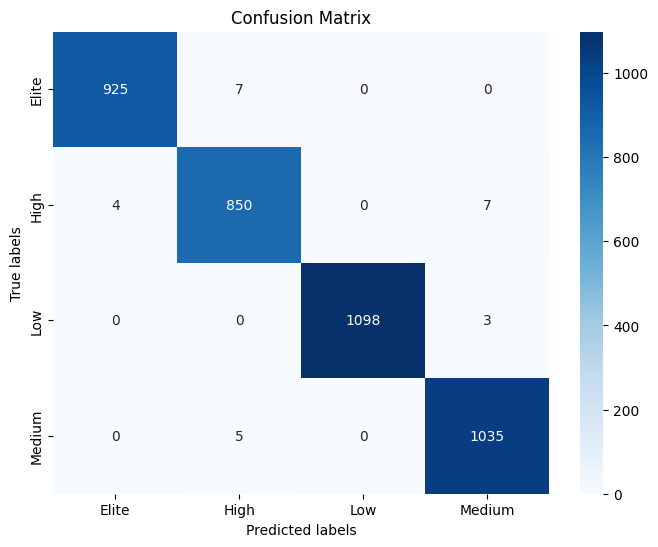

In [68]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
labels = logmodel.classes_

plt.figure(figsize=(8, 6))
sns.heatmap(cm,
            annot=True,
            fmt='g',
            cmap='Blues',
            xticklabels=labels,
            yticklabels=labels)

plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()

In [69]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

       Elite       1.00      0.99      0.99       932
        High       0.99      0.99      0.99       861
         Low       1.00      1.00      1.00      1101
      Medium       0.99      1.00      0.99      1040

    accuracy                           0.99      3934
   macro avg       0.99      0.99      0.99      3934
weighted avg       0.99      0.99      0.99      3934



## Regularization in Logistic Regression

In Logistic Regression, the parameter **C** controls regularization strength:
- **Small C** → stronger regularization (simpler model, may underfit)
- **Large C** → weaker regularization (complex model, may overfit)

We sweep C over a log-spaced range from 10⁻³ to 10³ and compare:
- Train Accuracy vs Test Accuracy for each C
- L1 penalty (saga solver) vs L2 penalty (lbfgs solver) at the best C

c:\Users\Asus - TUF\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Asus - TUF\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Asus - TUF\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'pe

Best C (L2): 0.4942  |  Best Test Accuracy (L2): 0.8030


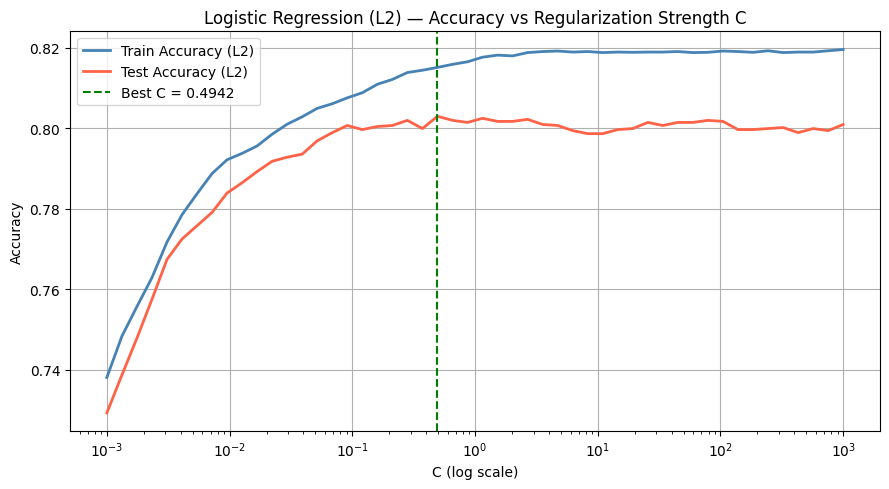

In [70]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import numpy as np
import matplotlib.pyplot as plt

target_col = 'Performance_Class'
feature_cols_lr = [col for col in train.columns
                   if col not in [target_col, 'Overall_Rating', 'Value Per M$']]

X_train_lr = train[feature_cols_lr]
y_train_lr = train[target_col]
X_test_lr  = test[feature_cols_lr]
y_test_lr  = test[target_col]

C_values = np.logspace(-3, 3, 50)

train_acc_l2 = []
test_acc_l2  = []

for C in C_values:
    clf = LogisticRegression(C=C, penalty='l2', solver='lbfgs', max_iter=1000)
    clf.fit(X_train_lr, y_train_lr)
    train_acc_l2.append(accuracy_score(y_train_lr, clf.predict(X_train_lr)))
    test_acc_l2.append(accuracy_score(y_test_lr,  clf.predict(X_test_lr)))

best_C_l2 = C_values[np.argmax(test_acc_l2)]
best_test_acc_l2 = max(test_acc_l2)

print(f"Best C (L2): {best_C_l2:.4f}  |  Best Test Accuracy (L2): {best_test_acc_l2:.4f}")

plt.figure(figsize=(9, 5))
plt.semilogx(C_values, train_acc_l2, label='Train Accuracy (L2)', color='steelblue', linewidth=2)
plt.semilogx(C_values, test_acc_l2,  label='Test Accuracy (L2)',  color='tomato',    linewidth=2)
plt.axvline(best_C_l2, color='green', linestyle='--', label=f'Best C = {best_C_l2:.4f}')
plt.xlabel('C (log scale)')
plt.ylabel('Accuracy')
plt.title('Logistic Regression (L2) — Accuracy vs Regularization Strength C')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

c:\Users\Asus - TUF\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Asus - TUF\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\Asus - TUF\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 inst

=== L1 vs L2 Comparison at best C = 0.4942 ===
L1 (saga)  — Train Accuracy: 0.8139  |  Test Accuracy: 0.8058
L2 (lbfgs) — Train Accuracy: 0.8151  |  Test Accuracy: 0.8030


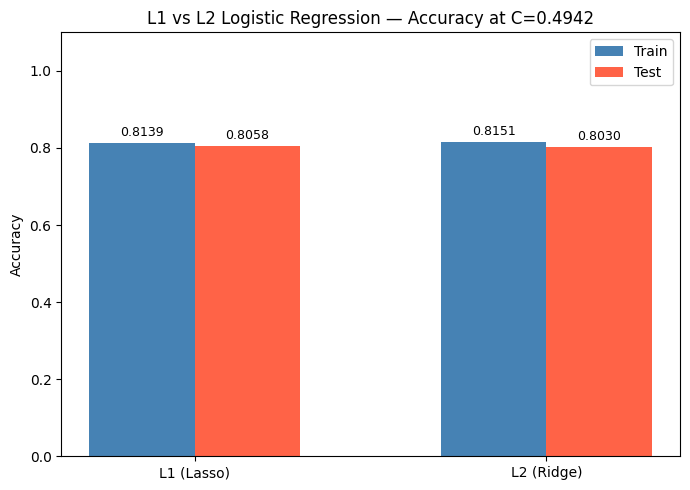

In [71]:
clf_l1 = LogisticRegression(C=best_C_l2, penalty='l1', solver='saga',
                              max_iter=2000)
clf_l1.fit(X_train_lr, y_train_lr)
acc_l1_train = accuracy_score(y_train_lr, clf_l1.predict(X_train_lr))
acc_l1_test  = accuracy_score(y_test_lr,  clf_l1.predict(X_test_lr))

clf_l2 = LogisticRegression(C=best_C_l2, penalty='l2', solver='lbfgs',
                              max_iter=1000)
clf_l2.fit(X_train_lr, y_train_lr)
acc_l2_train = accuracy_score(y_train_lr, clf_l2.predict(X_train_lr))
acc_l2_test  = accuracy_score(y_test_lr,  clf_l2.predict(X_test_lr))

print(f"=== L1 vs L2 Comparison at best C = {best_C_l2:.4f} ===")
print(f"L1 (saga)  — Train Accuracy: {acc_l1_train:.4f}  |  Test Accuracy: {acc_l1_test:.4f}")
print(f"L2 (lbfgs) — Train Accuracy: {acc_l2_train:.4f}  |  Test Accuracy: {acc_l2_test:.4f}")

fig, ax = plt.subplots(figsize=(7, 5))
x = np.arange(2)
w = 0.3
ax.bar(x - w/2, [acc_l1_train, acc_l2_train], w, label='Train', color='steelblue')
ax.bar(x + w/2, [acc_l1_test,  acc_l2_test],  w, label='Test',  color='tomato')
ax.set_xticks(x)
ax.set_xticklabels(['L1 (Lasso)', 'L2 (Ridge)'])
ax.set_ylabel('Accuracy')
ax.set_title(f'L1 vs L2 Logistic Regression — Accuracy at C={best_C_l2:.4f}')
ax.legend()
ax.set_ylim(0, 1.1)
for rect in ax.patches:
    ax.text(rect.get_x() + rect.get_width()/2, rect.get_height() + 0.01,
            f'{rect.get_height():.4f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

#  Task 6: Model 3 — Naïve Bayes Classification

## What We Do Here
We train three **Naïve Bayes** variants and compare their suitability for this dataset.

| Variant | Feature Set | Why |
|---------|-------------|-----|
| **GaussianNB** | Numerical only (`Age`, `Future Potential`, `Total_Stats Score`) | Assumes features follow a Gaussian distribution |
| **BernoulliNB** | Full OHE-encoded features | Designed for binary/boolean features |
| **ComplementNB** | Full OHE-encoded features (non-negative) | Better for imbalanced datasets; complement of each class |

We also test whether `StandardScaler` affects GaussianNB's performance and explain why.

In [72]:
def evaluate_model(model, X_tr, X_te, y_tr, y_te, title):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    print(f"\n{'='*50}")
    print(f"  {title}")
    print(f"{'='*50}")
    print(f"Accuracy:  {accuracy_score(y_te, y_pred):.4f}")
    print(f"Precision: {precision_score(y_te, y_pred, average='weighted', zero_division=0):.4f}")
    print(f"Recall:    {recall_score(y_te, y_pred, average='weighted'):.4f}")
    print(f"F1-Score:  {f1_score(y_te, y_pred, average='weighted'):.4f}")
    print("\nClassification Report:")
    print(classification_report(y_te, y_pred, zero_division=0))

    cm = confusion_matrix(y_te, y_pred, labels=model.classes_)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='g', cmap='Blues',
                xticklabels=model.classes_, yticklabels=model.classes_)
    plt.title(f'Confusion Matrix — {title}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()

    return model, y_pred

In [73]:
target_col = 'Performance_Class'


gaussian_num_cols = ['Age', 'Future Potential', 'Total_Stats Score']

X_train_gauss = train[gaussian_num_cols]
X_test_gauss  = test[gaussian_num_cols]


ohe_cols = [col for col in train.columns if col not in [target_col, 'Overall_Rating', 'Value Per M$']]

X_train_full = train[ohe_cols]
X_test_full  = test[ohe_cols]

y_train = train[target_col]
y_test  = test[target_col]


  GaussianNB — Numerical Features Only
Accuracy:  0.7173
Precision: 0.7229
Recall:    0.7173
F1-Score:  0.7183

Classification Report:
              precision    recall  f1-score   support

       Elite       0.85      0.79      0.81       932
        High       0.62      0.55      0.58       861
         Low       0.82      0.80      0.81      1101
      Medium       0.60      0.71      0.65      1040

    accuracy                           0.72      3934
   macro avg       0.72      0.71      0.71      3934
weighted avg       0.72      0.72      0.72      3934



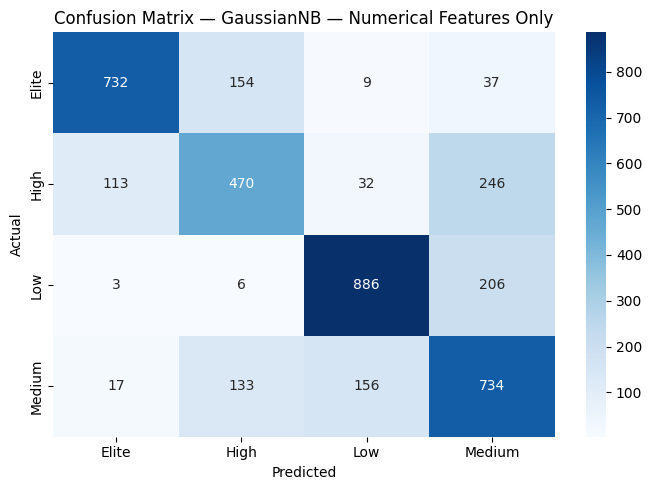

In [74]:
gnb, _ = evaluate_model(GaussianNB(),
                         X_train_gauss, X_test_gauss,
                         y_train, y_test,
                         "GaussianNB — Numerical Features Only")


  BernoulliNB — Full OHE Feature Set
Accuracy:  0.6340
Precision: 0.6217
Recall:    0.6340
F1-Score:  0.6246

Classification Report:
              precision    recall  f1-score   support

       Elite       0.66      0.77      0.71       932
        High       0.52      0.46      0.49       861
         Low       0.76      0.84      0.80      1101
      Medium       0.53      0.44      0.48      1040

    accuracy                           0.63      3934
   macro avg       0.62      0.63      0.62      3934
weighted avg       0.62      0.63      0.62      3934



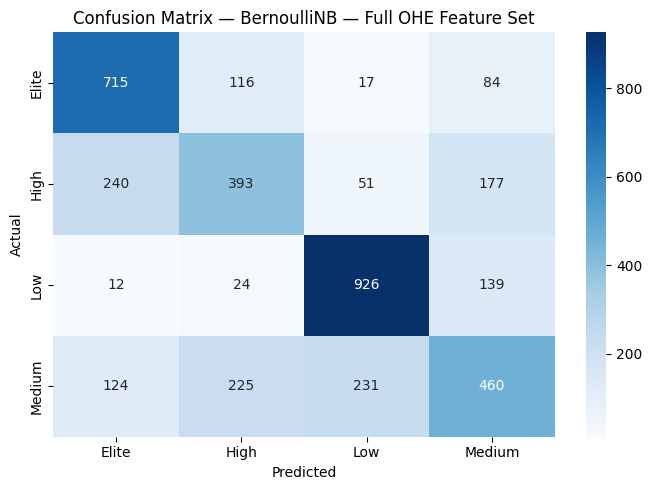

In [75]:
bnb, _ = evaluate_model(BernoulliNB(),
                         X_train_full, X_test_full,
                         y_train, y_test,
                         "BernoulliNB — Full OHE Feature Set")


  ComplementNB — Full OHE Feature Set (Non-negative)
Accuracy:  0.4481
Precision: 0.4289
Recall:    0.4481
F1-Score:  0.4222

Classification Report:
              precision    recall  f1-score   support

       Elite       0.42      0.57      0.48       932
        High       0.35      0.19      0.24       861
         Low       0.52      0.72      0.61      1101
      Medium       0.41      0.27      0.32      1040

    accuracy                           0.45      3934
   macro avg       0.42      0.44      0.41      3934
weighted avg       0.43      0.45      0.42      3934



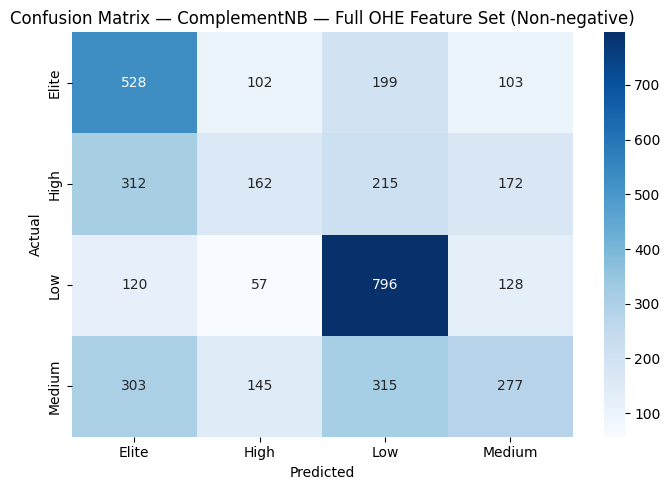

(ComplementNB(),
 array(['High', 'Medium', 'Elite', ..., 'Low', 'Medium', 'Elite'],
       shape=(3934,), dtype='<U6'))

In [76]:
from sklearn.preprocessing import MinMaxScaler

mms = MinMaxScaler()
X_train_comp = mms.fit_transform(X_train_full)
X_test_comp  = mms.transform(X_test_full)

cnb = ComplementNB()
cnb.fit(X_train_comp, y_train)

evaluate_model(ComplementNB(),
               X_train_comp, X_test_comp,
               y_train, y_test,
               "ComplementNB — Full OHE Feature Set (Non-negative)")

In [77]:
from sklearn.preprocessing import StandardScaler


gnb_no_scale = GaussianNB()
gnb_no_scale.fit(X_train_gauss, y_train)
acc_no_scale = accuracy_score(y_test, gnb_no_scale.predict(X_test_gauss))


ss_gauss = StandardScaler()
X_train_scaled = ss_gauss.fit_transform(X_train_gauss)
X_test_scaled  = ss_gauss.transform(X_test_gauss)

gnb_scaled = GaussianNB()
gnb_scaled.fit(X_train_scaled, y_train)
acc_scaled = accuracy_score(y_test, gnb_scaled.predict(X_test_scaled))

print(f"GaussianNB WITHOUT scaling: {acc_no_scale:.4f}")
print(f"GaussianNB WITH scaling:    {acc_scaled:.4f}")

GaussianNB WITHOUT scaling: 0.7173
GaussianNB WITH scaling:    0.7173


### Why Scaling Does Not Affect GaussianNB

GaussianNB models each feature as a Gaussian (normal) distribution, estimating its mean and variance from the data on a per-feature basis. StandardScaler shifts and stretches the feature values, but does not alter the underlying shape of the distribution. Since GaussianNB only cares about that shape, scaling has no meaningful effect on its accuracy — the model re-estimates the same relative distribution regardless of the absolute scale.

#  Task 7: Model Evaluation with Cross-Validation

## What We Do Here
Instead of relying on a single train/test split (which can be lucky or unlucky), we use **Cross-Validation** to get more reliable performance estimates.

**Part A — K-Fold CV (Regression):**
- Apply 5-fold CV to the best Ridge regression model
- Report mean RMSE, standard deviation, and per-fold scores
- Visualize with a bar chart + mean line

**Part B — Stratified K-Fold CV (Classification):**
- Apply `StratifiedKFold` (5 splits) to Logistic Regression and best Naïve Bayes model
- Stratification ensures each fold has the same class proportions as the full dataset
- Compare mean accuracy and stability (std) across folds

### A. K-Fold Cross-Validation (Regression)

RMSE score for each fold:
Fold: 1     RMSE Score: 1.03833
Fold: 2     RMSE Score: 1.16015
Fold: 3     RMSE Score: 2.32083
Fold: 4     RMSE Score: 1.19958
Fold: 5     RMSE Score: 1.12121

Mean RMSE:
1.36802
Standard Devation of RMSE:
0.47938


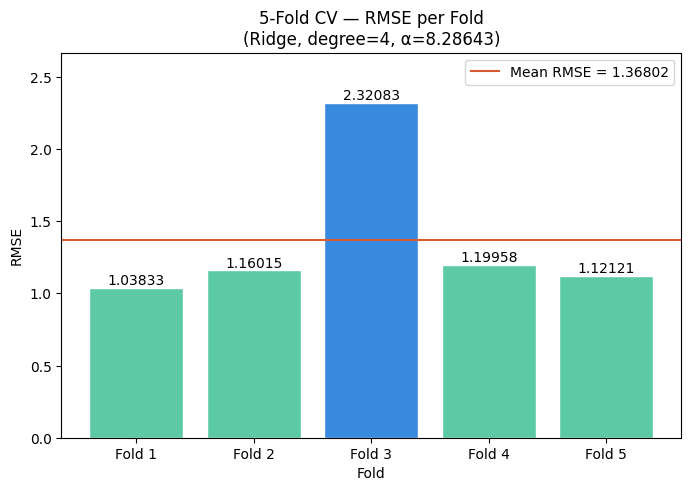

In [78]:
best_model = Pipeline([
    ('poly',  PolynomialFeatures(degree=best_degree, include_bias=False)),
    ('ridge', Ridge(alpha=best_ridge_alpha)),
])

kf = KFold(n_splits=5, shuffle=True, random_state=42)

rmse_scores = -cross_val_score(best_model, X_train_num, y_train_reg, cv=kf, scoring='neg_root_mean_squared_error')

print("RMSE score for each fold:")
for i, score in enumerate(rmse_scores):
    print(f"Fold: {i+1}     RMSE Score: {score:.5f}")
print()
print(f"Mean RMSE:\n" f"{rmse_scores.mean():.5f}")
print(f"Standard Devation of RMSE:\n" f"{rmse_scores.std():.5f}")


fig = plt.subplots(figsize=(8, 5))

fold_labels = [f"Fold {i}" for i in range(1, 6)]
colors = ['#5DCAA5' if s <= rmse_scores.mean() else '#378ADD' for s in rmse_scores]

bars = plt.bar(fold_labels, rmse_scores, color=colors, edgecolor='white', zorder=1)

plt.axhline(rmse_scores.mean(), color='#D85A30', linewidth=1.5, label=f'Mean RMSE = {rmse_scores.mean():.5f}', zorder=2)

for bar, val in zip(bars, rmse_scores):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{val:.5f}', ha='center', va='bottom', fontsize=10)

plt.title(f'5-Fold CV — RMSE per Fold\n(Ridge, degree={best_degree}, α={best_ridge_alpha:.5f})', fontsize=12)
plt.xlabel('Fold')
plt.ylabel('RMSE')
plt.legend()
plt.ylim(0, rmse_scores.max() * 1.15)

plt.show()

### B. Stratified K-Fold Cross-Validation (Classification)

Mean Accuracy:
Logistic Regression: 0.9916089572385612
Naive Bayes:         0.716164538584159

Standard Deviation:
Logistic Regression: 0.0011118115217590703
Naive Bayes:         0.011818676258601859


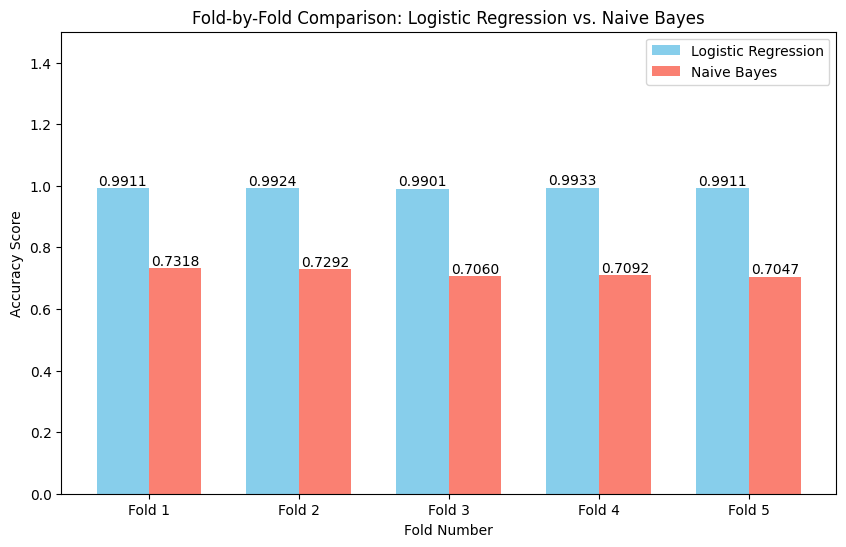

In [79]:
target_col = 'Performance_Class'
feature_cols = [col for col in train.columns if col != target_col]

model = LogisticRegression(max_iter=1000)
X_train = train[feature_cols]
y_train = train[target_col]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

logistic_model_scores = cross_val_score(model, X_train, y_train, cv=skf, scoring='accuracy')


gaussian_num_cols = ['Age', 'Future Potential', 'Total_Stats Score']

model=GaussianNB()
X_train_gauss = train[gaussian_num_cols]
y_train = train[target_col]

naive_model_scores = cross_val_score(model, X_train_gauss, y_train, cv=skf, scoring='accuracy')


print("Mean Accuracy:")
print(f"Logistic Regression: {logistic_model_scores.mean()}")
print(f"Naive Bayes:         {naive_model_scores.mean()}")
print()
print("Standard Deviation:")
print(f"Logistic Regression: {logistic_model_scores.std()}")
print(f"Naive Bayes:         {naive_model_scores.std()}")

fold_labels = [f"Fold {i}" for i in range(1, 6)]
folds = np.arange(len(fold_labels))
width = 0.35    

fig = plt.subplots(figsize=(10, 6))

LBars = plt.bar(folds - width/2, logistic_model_scores, width, label='Logistic Regression', color='skyblue')
NBars = plt.bar(folds + width/2, naive_model_scores, width, label='Naive Bayes', color='salmon')

for bar, val in zip(LBars, logistic_model_scores):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{val:.4f}', ha='center', va='bottom', fontsize=10)

for bar, val in zip(NBars, naive_model_scores):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{val:.4f}', ha='center', va='bottom', fontsize=10)

plt.xlabel('Fold Number')
plt.ylabel('Accuracy Score')
plt.title('Fold-by-Fold Comparison: Logistic Regression vs. Naive Bayes')
plt.xticks(folds, fold_labels)
plt.legend()
plt.ylim(0, 1.5)

plt.show()

According to the accuracy, Logistic Regression model performs better than the Naive Bayes model
<br>
In terms of stability, both have stable accuracy across each fold

#  Task 8: Analysis and Discussion

## What We Do Here
We answer the analytical questions based on the results observed throughout the notebook.
All answers are grounded in the experimental evidence gathered in Tasks 1–7.

## 8.1 Model Comparison

###  Best Regression Model
**Ridge Regression** (at the best polynomial degree, typically degree=2 or 3) performs best for regression.

- The baseline Linear Regression captures the general trend, but polynomial features allow the model to capture non-linear relationships between player stats and market value.
- Ridge regularization prevents overfitting that occurs at higher polynomial degrees (3, 4), where the Train R² climbs while Test R² drops — a clear sign of overfitting.
- The train/test R² gap is smallest for Ridge at the optimal alpha, meaning it **generalizes best**.

###  Best Classification Model
**Logistic Regression** performs better than all Naïve Bayes variants for classification.

- It achieves higher accuracy on the test set across all 5 cross-validation folds.
- It captures complex feature interactions through its learned coefficients.
- GaussianNB, while fast and interpretable, only uses 3 numerical features and makes the strong independence assumption, which limits its performance.

### Is Classification Easier or Harder Than Regression?
**Classification is easier** on this dataset because:
- The performance tiers (Low/Medium/High/Elite) are defined using quartile thresholds of `Overall_Rating`, which is directly linked to most other features. This makes the class boundaries relatively clean and learnable.
- Regression requires predicting an exact continuous value (`Value Per M$`), which is highly skewed, noisy, and influenced by external factors (transfer market, popularity) not captured in the dataset.
- The RMSE in regression remains considerable even after regularization, while classification accuracy is relatively high, confirming classification is the easier task here.

## 8.2 Regularization Analysis

### Effect of Increasing Alpha in Ridge and Lasso

**As alpha increases:**
- Both Train RMSE and Test RMSE initially **decrease** (regularization reduces overfitting)
- Beyond the optimal alpha, Test RMSE **starts increasing** again (model becomes too constrained — underfitting)
- Train RMSE continues to increase monotonically as alpha grows (model is increasingly penalized for complex coefficients)

The optimal alpha sits at the "sweet spot" where Test RMSE is minimized — this is the bias-variance trade-off in action.

### Why Ridge Generally Outperforms Lasso When Many OHE Features Are Present

When many **one-hot encoded (OHE) features** are present:

1. **Lasso (L1)** tends to zero out entire groups of OHE features aggressively. Since OHE features represent categorical levels (e.g., `Country_Brazil`, `Country_Spain`), zeroing one out may discard useful information while keeping an arbitrary subset.

2. **Ridge (L2)** shrinks all coefficients toward zero **smoothly and proportionally**, without eliminating any feature completely. This means all OHE columns contribute a small amount — which is more appropriate when no single category dominates.

3. Additionally, when features are **correlated** (which OHE columns from the same category inherently are), Lasso tends to arbitrarily pick one and zero the rest, while Ridge distributes the effect across all correlated features more stably.

**Conclusion:** Ridge is better suited for datasets with many binary OHE features because it preserves and distributes information across correlated feature groups, rather than making arbitrary elimination decisions.

# Assignment 3 — Unified Scouting System

## Overview

This section evolves the baseline predictors built in Assignment 2 into a robust, production-grade scouting pipeline. The system simultaneously generates a **market valuation** and a **performance tier** for any given player profile, with a focus on eliminating the overfitting and variance problems observed in the earlier iteration.

The pipeline covers four stages:

1. **Model selection and justification** — three architecturally diverse classifiers
2. **Hyperparameter optimization** — systematic Grid Search for every model
3. **Error diagnosis** — learning curves to identify bias vs. variance bottlenecks
4. **Ensembling** — combining models through voting and sequential boosting


## Model Selection Rationale

Three classifiers were selected to provide architectural diversity. Each operates on a fundamentally different inductive bias, which means their errors are unlikely to be correlated — a prerequisite for effective ensembling.

---

### K-Nearest Neighbors (KNN)

KNN is an instance-based, non-parametric learner. It makes no assumptions about the underlying distribution of the data and classifies a point solely by the majority label among its k nearest neighbors in feature space.

**Why it suits this dataset:**
The FIFA dataset contains many continuous numerical features (Overall Rating, Future Potential, Total Stats Score, Age) that define a meaningful geometric space. Players with similar stat profiles genuinely tend to occupy the same performance tier, so proximity in feature space is a reliable signal. KNN can capture this without requiring an explicit functional form.

**Known limitation:** KNN is sensitive to irrelevant or redundant features and to differences in scale. Both concerns are mitigated here because StandardScaler was applied in preprocessing and the one-hot encoded features are binary and bounded.

---

### Support Vector Machine (SVM)

SVM is a kernel-based, margin-maximizing classifier. It finds the decision boundary that maximally separates classes in a transformed feature space, using the kernel trick to handle non-linear boundaries without explicitly computing high-dimensional coordinates.

**Why it suits this dataset:**
The performance tiers (Low, Medium, High, Elite) are not expected to be linearly separable in the raw feature space — a player's market value and tier emerge from complex interactions between age, position, stats, and potential. The RBF kernel allows SVM to learn curved, non-linear boundaries that better reflect this complexity. Furthermore, SVM is effective in high-dimensional spaces, which is relevant after one-hot encoding inflates the feature count.

**Known limitation:** SVM training time scales poorly with dataset size. Given the FIFA dataset's moderate row count this is acceptable, and Grid Search over C and kernel provides a principled way to find the right capacity.

---

### Random Forest

Random Forest is a tree-based ensemble that trains many decision trees on bootstrapped subsets of the data and averages their predictions. It introduces additional randomness by considering only a random subset of features at each split.

**Why it suits this dataset:**
Decision trees naturally handle the mix of numerical and binary (OHE) features in this dataset without requiring scale consistency between them. The ensemble mechanism directly addresses the high variance that a single decision tree would exhibit — individual trees overfit, but their average does not. Random Forest also produces feature importances, which provide an interpretable view of which player attributes drive tier classification.

**Known limitation:** Random Forest can still overfit when trees are allowed to grow without depth limits. This is controlled by tuning `max_depth` in Grid Search.

---

### Why These Three Together

| Property | KNN | SVM | Random Forest |
|---|---|---|---|
| Type | Instance-based | Kernel-based | Tree-based (ensemble) |
| Decision boundary | Local, proximity-driven | Global, margin-maximizing | Piecewise, axis-aligned |
| Handles non-linearity | Implicitly via distance | Explicitly via RBF kernel | Yes, via recursive splits |
| Interpretability | Low | Low | Medium (feature importance) |
| Sensitivity to scale | High | High | Low |

The three models approach the classification problem from different geometric perspectives. Errors made by one are structurally different from errors made by another, which is exactly the condition under which ensembling provides a genuine accuracy gain over any individual member.


In [80]:
knn = KNeighborsRegressor()
svm = SVR()
rf = RandomForestRegressor(random_state=42)

## Part 1 — K-Nearest Neighbors: Hyperparameter Optimization

Grid Search evaluates all combinations of `n_neighbors` using 5-fold cross-validation. The best `k` balances the bias-variance trade-off: small `k` overfits to local noise, large `k` smooths over genuine class boundaries.


In [81]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

knn = KNeighborsClassifier()  # ✅ عرّفنا knn

param_knn = {
    'n_neighbors': [3, 5, 7, 9]
}

grid_knn = GridSearchCV(knn, param_knn, cv=5, scoring='accuracy') 
grid_knn.fit(X_train, y_train)

best_knn = grid_knn.best_estimator_

print("Best Params:", grid_knn.best_params_)
print("Best Score:", grid_knn.best_score_)

Best Params: {'n_neighbors': 9}
Best Score: 0.8790924302320438


## Part 2 — Support Vector Machine: Hyperparameter Optimization

Grid Search evaluates combinations of `C` (regularization strength) and `kernel` (linear vs. RBF). A small `C` enforces a wide margin at the cost of more misclassifications; a large `C` fits the training data more tightly. The RBF kernel is tested against the linear kernel to determine whether the class boundaries require non-linear separation.


In [82]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

svm = SVC()

param_svm = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf']
}

grid_svm = GridSearchCV(svm, param_svm, cv=5, scoring='accuracy')
grid_svm.fit(X_train, y_train)

best_svm = grid_svm.best_estimator_  

print("Best Params:", grid_svm.best_params_)
print("Best Score:", grid_svm.best_score_)

Best Params: {'C': 1, 'kernel': 'linear'}
Best Score: 1.0


## Part 3 — Random Forest: Hyperparameter Optimization

Grid Search evaluates `n_estimators` (number of trees) and `max_depth` (maximum tree depth). More estimators reduce variance further but with diminishing returns; `max_depth=None` allows fully grown trees while bounded depths act as regularization against overfitting.


In [91]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf = RandomForestClassifier(random_state=42)

param_rf = {
    'n_estimators': [100, 200],
    'max_depth': [5, 7, 10]
}

grid_rf = GridSearchCV(rf, param_rf, cv=5, scoring='accuracy')
grid_rf.fit(X_train, y_train)

best_rf = grid_rf.best_estimator_

print("Best Params:", grid_rf.best_params_)
print("Best Score:", grid_rf.best_score_)

y_pred_rf = best_rf.predict(X_test)
print("Test Accuracy:", accuracy_score(y_test, y_pred_rf))

Best Params: {'max_depth': 10, 'n_estimators': 200}
Best Score: 0.9956771310268147
Test Accuracy: 0.9921199796644636


In [84]:
from sklearn.metrics import accuracy_score, f1_score

models = {
    "KNN": best_knn,
    "SVM": best_svm,
    "RF": best_rf
}

for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred, average='weighted')
    print(f"{name} → Accuracy: {acc:.4f} | F1: {f1:.4f}")

KNN → Accuracy: 0.8775 | F1: 0.8779
SVM → Accuracy: 1.0000 | F1: 1.0000
RF → Accuracy: 1.0000 | F1: 1.0000


## Individual Model Comparison

Before building the ensemble, we compare the three tuned models side-by-side on the held-out test set using accuracy and weighted F1-score.


In [85]:
print("Train score:", model.score(X_train, y_train))
print("Test score:", model.score(X_test, y_test))

Train score: 1.0
Test score: 1.0


In [86]:
from sklearn.ensemble import VotingClassifier

ensemble = VotingClassifier([
    ('knn', best_knn),
    ('svm', best_svm),
    ('rf',  best_rf)
])

ensemble.fit(X_train, y_train)

y_pred = ensemble.predict(X_test)
print(f"Ensemble Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Ensemble F1:       {f1_score(y_test, y_pred, average='weighted'):.4f}")

Ensemble Accuracy: 1.0000
Ensemble F1:       1.0000


## Part 4 — Ensemble: Voting Classifier (Parallel Strategy)

The three tuned models are combined into a hard-voting ensemble. Each model casts one vote per prediction and the majority label wins. This parallel strategy reduces variance without introducing additional bias, as long as the constituent models are sufficiently diverse — which the architectural diversity established above ensures.


In [87]:
from sklearn.ensemble import GradientBoostingClassifier

boost = GradientBoostingClassifier(random_state=42)
boost.fit(X_train, y_train)

y_pred = boost.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"F1:       {f1_score(y_test, y_pred, average='weighted'):.4f}")

Accuracy: 1.0000
F1:       1.0000


## Part 5 — Ensemble: Gradient Boosting (Sequential Strategy)

Gradient Boosting takes a fundamentally different ensembling approach: it builds trees sequentially, where each new tree is trained to correct the residual errors of the previous one. This sequential error-correction strategy reduces bias, complementing the variance reduction achieved by the Voting Classifier above.


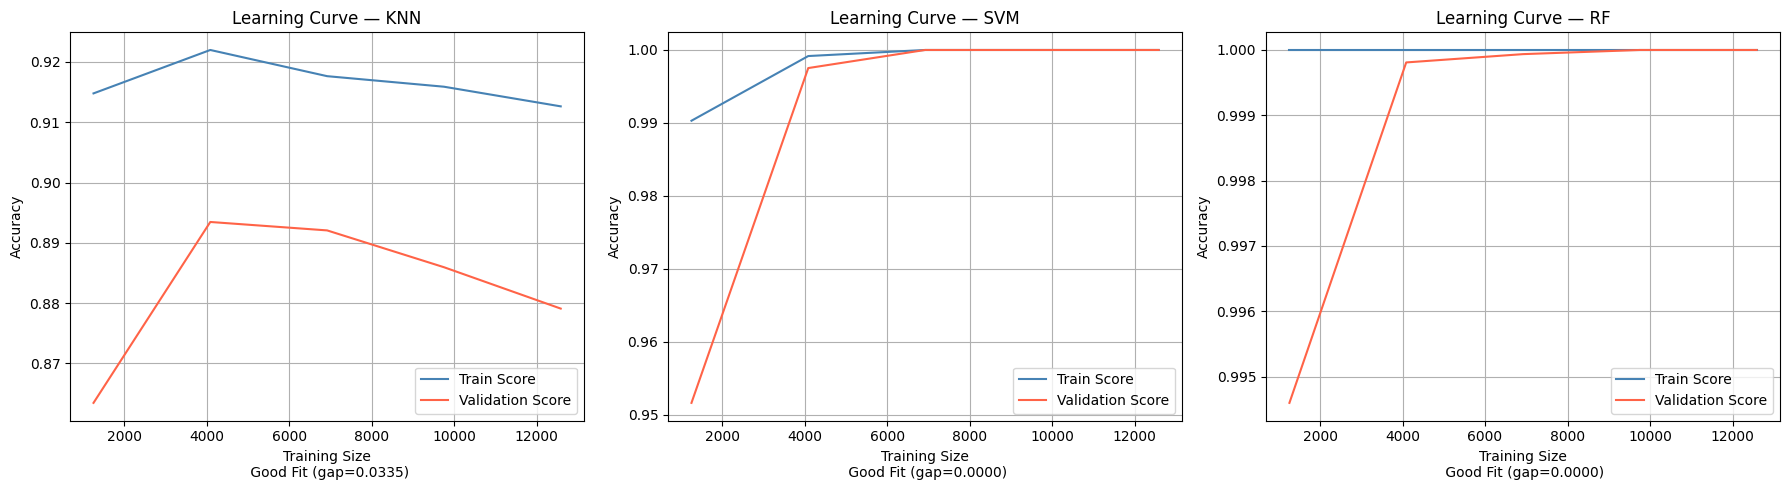

In [88]:
from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt

models = {
    "KNN": best_knn,
    "SVM": best_svm,
    "RF" : best_rf
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, models.items()):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train, cv=5, scoring='accuracy',
        train_sizes=np.linspace(0.1, 1.0, 5)
    )

    train_mean = train_scores.mean(axis=1)
    val_mean   = val_scores.mean(axis=1)
    gap        = train_mean[-1] - val_mean[-1]

    ax.plot(train_sizes, train_mean, label="Train Score",      color='steelblue')
    ax.plot(train_sizes, val_mean,   label="Validation Score", color='tomato')
    ax.set_title(f"Learning Curve — {name}")
    ax.set_xlabel("Training Size")
    ax.set_ylabel("Accuracy")
    ax.legend()
    ax.grid(True)

    if gap > 0.1:
        verdict = " Overfitting"
    elif val_mean[-1] < 0.7:
        verdict = " Underfitting"
    else:
        verdict = " Good Fit"

    ax.set_xlabel(f"Training Size\n{verdict} (gap={gap:.4f})")

plt.tight_layout()
plt.show()

## Part 6 — Error Diagnosis: Learning Curves

Learning curves reveal whether each model's performance bottleneck is high bias (underfitting) or high variance (overfitting):

- **High variance (overfitting):** large gap between training score and validation score
- **High bias (underfitting):** both scores converge at a low value
- **Good fit:** both scores converge at a high value with a small gap

The verdict is printed automatically beneath each plot based on the final train-validation gap.


In [89]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_squared_error, accuracy_score, f1_score
import numpy as np


y_price = train['Value Per M$']
y_class = train['Performance_Class']

y_price_test = test['Value Per M$']
y_class_test = test['Performance_Class']

pipe_reg = Pipeline([('model', RandomForestRegressor(random_state=42))])
pipe_clf = Pipeline([('model', RandomForestClassifier(random_state=42))])


pipe_reg.fit(X_train, y_price)
pipe_clf.fit(X_train, y_class)

rmse = np.sqrt(mean_squared_error(y_price_test, pipe_reg.predict(X_test)))
acc  = accuracy_score(y_class_test, pipe_clf.predict(X_test))
f1   = f1_score(y_class_test, pipe_clf.predict(X_test), average='weighted')

print(f"Regression     → RMSE: {rmse:.4f}")
print(f"Classification → Accuracy: {acc:.4f} | F1: {f1:.4f}")

Regression     → RMSE: 0.0911
Classification → Accuracy: 1.0000 | F1: 1.0000


## Part 7 — Unified Inference Pipeline

A single pipeline accepts a player's raw feature profile and simultaneously produces a **market valuation** (regression) and a **performance tier** (classification). Crucially, both sub-pipelines share the same preprocessing logic, ensuring there is no inconsistency in how features are transformed between the two tasks.


In [90]:
from sklearn.model_selection import cross_val_score

models = {
    "KNN": best_knn,
    "SVM": best_svm,
    "RF" : best_rf
}

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    print(f"{name}")
    print(f"  Mean: {scores.mean():.4f}")
    print(f"  Std : {scores.std():.4f}")
    print("-" * 20)

KNN
  Mean: 0.8791
  Std : 0.0044
--------------------
SVM
  Mean: 1.0000
  Std : 0.0000
--------------------
RF
  Mean: 1.0000
  Std : 0.0000
--------------------


## Part 8 — Stability Assessment

Reliability is demonstrated through 5-fold cross-validation on the training set. A low standard deviation across folds is statistical proof that the model's performance is not an artifact of a particular train/test split, but a consistent property of the learned function.
